In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

project_root = '/content/drive/MyDrive/COMP5625M_Summative Assessment_2026'
os.chdir(project_root)

print("Current working directory:", os.getcwd())
print("Files in project root:")
print(os.listdir())

Current working directory: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026
Files in project root:
['coco_subset_meta.csv', 'coco_features.pt', 'Comp5625M_logo.jpg', 'model_CLIP.py', 'model_S.pt', 'model_L.pt', 'comp5625M_figure_v3.jpg', 'helperDL.py', 'coco_captions.csv', 'notebook_zh_explained.md', 'COMP5625M_assessment2026_Summative_vFinal.ipynb', '.ipynb_checkpoints', 'tinyimagenet30', 'cifar10_data', 'coco', 'tinyimagenet30_final_model_checkpoint.pt', 'nplw0197.csv', '__pycache__', 'Images', 'coco_default_parameters.png', 'coco_default_parameters_decoder.ckpt', 'coco_new_parameters.png', 'coco_new_parameters_best_decoder.ckpt', 'clipcap-base-captioning-ft-hl-scenes']


In [ ]:
print("tinyimagenet30 exists:", os.path.exists('tinyimagenet30'))
print("train_set exists:", os.path.exists('tinyimagenet30/train_set'))
print("test_set exists:", os.path.exists('tinyimagenet30/test_set'))

if os.path.exists('tinyimagenet30/train_set'):
    print("train_set first few entries:")
    print(os.listdir('tinyimagenet30/train_set')[:10])

tinyimagenet30 exists: True
train_set exists: True
test_set exists: True
train_set first few entries:
['train_set']


## COMP5625M Deep Learning - Practical Assessment [100 Marks]


<div class="logos"><img src="Comp5625M_logo.jpg" width="220px" align="right"></div>

This assessment is divided into two parts:
> 1. Image classification using a convolutional neural network (CNN), training your model, evaluating your model, understanding fine-tuning, handling overfitting  [60 Marks]
> 2. Use of a Recurrent Neural Network (RNN) to predict texts for image captioning, and use of large language models (LLMs) for this task [40 Marks]


The maximum number of marks for each part is shown in the section headers. As indicated in the main heading above, the overall assessment carries a maximum of 100 marks.

This summative assessment is weighted 50% of the final grade for the module.


### Motivation

Through this coursework, you will:

> 1. Understand and implement a convolutional neural network (CNN) and see how this can be used for a classification problem.
> 2. Practice building, evaluating, and finetuning your CNN on an image dataset from development to testing stage.
> 3. You will learn to tackle overfitting problem using strategies such as data augmentation and drop out.
> 4. Compare your model performance and accuracy with others, such as the leaderboard on Kaggle.
> 5. Use a Recurrent Neural Network (RNN) to predict the caption of an image from established word vocabularies.
> 6. Understand and visualise text predictions for a given image.
> 7. Learn to use transformers for image embedding and transformer-based large language models for text embedding learning.


### Setup and resources

You must work using this provided template notebook.

Having a GPU will speed up the training process. See the provided document on Minerva about setting up a working environment for various ways to access a GPU.

Please implement the coursework using **Python and PyTorch**, and refer to the notebooks and exercises provided.


### Submission

Please submit the following:

> 1. Your completed Jupyter notebook file, without removing anything in the template, in **.ipynb format.**
> 2. The **.html version** of your notebook; File > Download as > HTML (.html). Check that all cells have been run and all outputs (including all graphs you would like to be marked) displayed in the .html for marking.
> 3. Your selected image from section 2.4.2 "Failure analysis"

Final note:

> **Please display everything that you would like to be marked. Under each section, put the relevant code containing your solution. You may re-use functions you defined previously, but any new code must be in the relevant section.** Feel free to add as many code cells as you need under each section.


Your student username (for example, ```sc15jb```):

nplw0197

Your full name:

Yichen Nie

### Part I: Image Classification [60 marks]

#### Dataset
This coursework will use a subset of images from Tiny ImageNet, which is a subset of the [ImageNet dataset](https://www.image-net.org/update-mar-11-2021.php). Our subset of Tiny ImageNet contains **30 different categories**, we will refer to it as TinyImageNet30. The training set has 450 resized images (64x64 pixels) for each category (13,500 images in total). You can download the training and test set from the Kaggle website:

>[Direct access of data is possible by clicking here, please use your university email to access this](https://leeds365-my.sharepoint.com/:u:/g/personal/scssali_leeds_ac_uk/ESF87mN6kelIkjdISkaRow8BublW27jB-P8eWV6Rr4rxtw?e=SPASDB)

>[To submit your results on the Kaggle competition. You can also access data here](https://www.kaggle.com/t/2140e7b8d877463192f4e6874a1031d2) **(To be launched on 8th March 2026)**

To access the dataset, you will need an account on the Kaggle website. Even if you have an existing Kaggle account, please carefully adhere to these instructions, or we may not be able to locate your entries:

> 1. Use your **university email** to register a new account.
> 2. Set your **Kaggle account NAME** to your university username, for example, ``sc15jb`` (see the ``note`` below)

``Note:`` If the name is already taken in Kaggle then please use a similar pseudo name and add a note in your submission with the name you have used in Kaggle.

#### Submitting your test result to Kaggle leaderboard
The class Kaggle competition also includes a blind test set, which will be used in Question 1 for evaluating your custom model's performance on a test set. The competition website will compute the test set accuracy, as well as position your model on the class leaderboard. More information is provided in the related section below.


## Required packages

[1] [numpy](http://www.numpy.org) is package for scientific computing with python

[2] [h5py](http://www.h5py.org) is package to interact with compactly stored dataset

[3] [matplotlib](http://matplotlib.org) can be used for plotting graphs in python

[4] [pytorch](https://pytorch.org/docs/stable/index.html) is library widely used for bulding deep-learning frameworks

Feel free to add to this section as needed. Examples for importing some libraries is provided for you below.

You may need to install these packages using [pip](https://pypi.org/project/opencv-python/) or [conda](https://anaconda.org/conda-forge/opencv).

In [ ]:
import cv2
import math

import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.hub import load_state_dict_from_url

from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
# always check your version
print(torch.__version__)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

2.10.0+cpu
Using device: cpu


One challenge of building a deep learning model is to choose an architecture that can learn the features in the dataset without being unnecessarily complex. The first part of the coursework involves building a CNN and training it on TinyImageNet30.

### **Overview of image classification:**

**1. Function implementation** [10 marks]

*   **1.1** PyTorch ```Dataset``` and ```DataLoader``` classes (4 marks)
*   **1.2** PyTorch ```Model``` class for 5-layer CNN model (6 marks)

**2. Model training** [24 marks]
*   **2.1** Training on TinyImageNet30 dataset (6 marks)
*   **2.2** Generating confusion matrices and ROC curves (6 marks)
*   **2.3** Strategies for tackling overfitting (12 marks)
    *   **2.3.1** Data augmentation
    *   **2.3.2** Dropout
    *   **2.3.3** Hyperparameter tuning (e.g. changing learning rate)
            
**3. Model testing** [10 marks]
*   **3.1**   Testing your final model in (2) on test set - code to do this (4 marks)
*   **3.2**   Uploading your result to Kaggle  (6 marks)

**4. Model Fine-tuning on CIFAR10 dataset** [16 marks]
*   **4.1** Fine-tuning your model (initialise your model with pretrained weights from (2)) (6 marks)
*   **4.2** Fine-tuning model with frozen base convolution layers (6 marks)
*   **4.3** Compare complete model retraining with pretrained weights and with frozen layers. Comment on what you observe. (4 marks)


<!-- **5. Model comparison** [16 marks]
*   **5.1**   Load pretrained AlexNet and finetune on TinyImageNet30 until model convergence (8 marks)
*   **5.2**   Compare the results of your model with pretrained AlexNet on the same validation set. Provide performance values (loss graph, confusion matrix, top-1 accuracy, execution time) (8 marks) -->
<!--
**6. Interpretation of results** (14 marks)
*   **6.1** Implement grad-CAM for your model and AlexNet (6 marks)
*   **6.2** Visualise and compare your results from your model and AlexNet (4 marks)
*   **6.3** Provide comment on (4 marks)
    - why the network predictions were correct or not correct in your predictions?
    - what can you do to improve your results further?

**7. Residual connection for deeper network** (9 marks)
*   **7.1** Implement a few residual layers in AlexNet and retrain on TinyImageNet30. You can change network size if you wish. (6 marks)
*   **7.2** Comment on why such connections are important and why this impacted your results in terms of loss and accuracy (if it did!) (3 marks)

**Quality of your report** (2 marks) -->


## 1 Implement a CNN network and dataset class [10 marks]


### 1.1 Dataset class (4 marks)

Write a PyTorch ```Dataset``` class (an example [here](https://www.askpython.com/python-modules/pytorch-custom-datasets) for reference) which loads the TinyImage30 dataset and ```DataLoaders``` for training and validation sets.

In [ ]:
# Optional for Google Colab: copy TinyImageNet30 from Google Drive to local runtime storage
import glob
import shutil
from pathlib import Path

COLAB_LOCAL_DATA_DIR = Path("/content/tinyimagenet30")
candidate_drive_dirs = [
    Path("/content/drive/MyDrive/tinyimagenet30"),
    Path("/content/drive/MyDrive/COMP5625M_Summative Assessment_2026/COMP5625M_Summative Assessment_2026/tinyimagenet30"),
]

source_data_dir = next((path for path in candidate_drive_dirs if path.exists()), None)

if source_data_dir is None:
    matches = glob.glob("/content/drive/MyDrive/**/tinyimagenet30", recursive=True)
    if matches:
        source_data_dir = Path(matches[0])

if source_data_dir is None:
    raise FileNotFoundError("Could not find 'tinyimagenet30' inside /content/drive/MyDrive. Please update source_data_dir manually.")

if not COLAB_LOCAL_DATA_DIR.exists():
    print(f"Copying data from {source_data_dir} to {COLAB_LOCAL_DATA_DIR} ...")
    shutil.copytree(source_data_dir, COLAB_LOCAL_DATA_DIR)
    print("Copy completed.")
else:
    print(f"Local copy already exists at {COLAB_LOCAL_DATA_DIR}.")

print(f"Using local dataset folder: {COLAB_LOCAL_DATA_DIR}")

Copying data from /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/tinyimagenet30 to /content/tinyimagenet30 ...
Copy completed.
Using local dataset folder: /content/tinyimagenet30


In [ ]:
# TO COMPLETE
import os
from torch.utils.data import Dataset, DataLoader

TINY_IMAGENET30_ROOT = "/content/tinyimagenet30/train_set"
VALID_RATIO = 0.2
SPLIT_SEED = 0
BATCH_SIZE = 64
NUM_WORKERS = 0
IMG_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".JPEG", ".JPG", ".PNG", ".BMP")

train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

valid_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

def is_image_file(file_name):
    return file_name.endswith(IMG_EXTENSIONS)

def has_images_in_tree(folder_path):
    for _, _, file_names in os.walk(folder_path):
        if any(is_image_file(file_name) for file_name in file_names):
            return True
    return False

def resolve_tinyimagenet30_train_root(root_dir):
    current_dir = os.path.abspath(root_dir)

    while True:
        if not os.path.isdir(current_dir):
            raise FileNotFoundError(f"Training directory not found: {current_dir}")

        subdirs = sorted([
            folder_name for folder_name in os.listdir(current_dir)
            if os.path.isdir(os.path.join(current_dir, folder_name))
        ])

        if len(subdirs) == 1:
            current_dir = os.path.join(current_dir, subdirs[0])
            continue

        class_dirs = [
            folder_name for folder_name in subdirs
            if has_images_in_tree(os.path.join(current_dir, folder_name))
        ]

        if len(class_dirs) > 1:
            return current_dir

        raise ValueError(
            f"Could not locate class folders containing images under: {os.path.abspath(root_dir)}"
        )

def build_tinyimagenet30_samples(root_dir):
    root_dir = resolve_tinyimagenet30_train_root(root_dir)

    class_names = sorted([
        folder_name for folder_name in os.listdir(root_dir)
        if os.path.isdir(os.path.join(root_dir, folder_name))
        and has_images_in_tree(os.path.join(root_dir, folder_name))
    ])

    class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
    samples = []

    for class_name in class_names:
        class_dir = os.path.join(root_dir, class_name)
        for current_dir, _, file_names in os.walk(class_dir):
            for file_name in sorted(file_names):
                file_path = os.path.join(current_dir, file_name)
                if os.path.isfile(file_path) and is_image_file(file_name):
                    samples.append((file_path, class_to_idx[class_name]))

    return samples, class_to_idx

class TinyImageNet30Dataset(Dataset):
    def __init__(self, samples, class_to_idx, transform=None):
        self.samples = samples
        self.class_to_idx = class_to_idx
        self.idx_to_class = {idx: class_name for class_name, idx in class_to_idx.items()}
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]
        image = Image.open(image_path).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, label

def create_tinyimagenet30_dataloaders(root_dir=TINY_IMAGENET30_ROOT, valid_ratio=VALID_RATIO, batch_size=BATCH_SIZE, seed=SPLIT_SEED, num_workers=NUM_WORKERS):
    samples, class_to_idx = build_tinyimagenet30_samples(root_dir)

    if len(samples) == 0:
        raise ValueError(f"No image files were found under: {os.path.abspath(root_dir)}")

    generator = torch.Generator().manual_seed(seed)
    shuffled_indices = torch.randperm(len(samples), generator=generator).tolist()

    split_idx = int(len(samples) * (1 - valid_ratio))
    train_indices = shuffled_indices[:split_idx]
    valid_indices = shuffled_indices[split_idx:]

    train_samples = [samples[idx] for idx in train_indices]
    valid_samples = [samples[idx] for idx in valid_indices]

    train_dataset = TinyImageNet30Dataset(train_samples, class_to_idx, transform=train_transform)
    valid_dataset = TinyImageNet30Dataset(valid_samples, class_to_idx, transform=valid_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return train_dataset, valid_dataset, train_loader, valid_loader, class_to_idx

train_dataset, valid_dataset, train_loader, valid_loader, class_to_idx = create_tinyimagenet30_dataloaders()
idx_to_class = {idx: class_name for class_name, idx in class_to_idx.items()}

print(f"Number of classes: {len(class_to_idx)}")
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(valid_dataset)}")

Number of classes: 30
Training samples: 10800
Validation samples: 2700


### 1.2 Define a CNN model class (6 marks)

<u>Create a new model class using a combination of:</u>
- Convolution layers
- Activation functions (e.g. ReLU)
- Maxpooling layers
- Fully connected layers
- Loss function
- Optimiser

*Please note that the network should be at least a few layers for the model to perform well.*

In [ ]:
# TO COMPLETE
# define a CNN Model class - ideally 5-7 convolutional layers

class TinyImageNetCNN(nn.Module):
    def __init__(self, num_classes=30):
        super(TinyImageNetCNN, self).__init__()

        def conv_block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 32),
            nn.MaxPool2d(kernel_size=2, stride=2),

            conv_block(32, 64),
            conv_block(64, 64),
            nn.MaxPool2d(kernel_size=2, stride=2),

            conv_block(64, 128),
            conv_block(128, 128),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

## 2 Model training [24 marks]


### 2.1 Train a CNN model - show loss and accuracy graphs side by side (6 marks)

Train your model on the TinyImageNet30 dataset. Split the data into train and validation sets to determine when to stop training. Use seed at 0 for reproducibility and test_ratio=0.2 (validation data)

Display the graph of training and validation loss over epochs and accuracy over epochs to show how you determined the optimal number of training epochs. A top-*k* accuracy implementation is provided for you below.

> Please leave the graph clearly displayed. Please use the same graph to plot graphs for both train and validation.


In [ ]:
# (HelperDL function) -- Define top-*k* accuracy (**new**)
def topk_accuracy(output, target, topk=(1,)):
    """Computes the precision@k for the specified values of k"""
    maxk = max(topk)
    batch_size = target.size(0)
    _, pred = output.topk(maxk, 1, True, True)
    pred = pred.t()
    correct = pred.eq(target.view(1, -1).expand_as(pred))

    res = []
    for k in topk:
        correct_k = correct[:k].view(-1).float().sum(0)
        res.append(correct_k.mul_(100.0 / batch_size))
    return res

In [ ]:
#TO COMPLETE --> Running your CNN model class
import copy
import random

SEED = 0
CNN_NUM_EPOCHS = 20
CNN_LEARNING_RATE = 1e-3
CNN_WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

model = TinyImageNetCNN(num_classes=30).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=CNN_LEARNING_RATE, weight_decay=CNN_WEIGHT_DECAY)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

cnn_history = {
    "train_loss": [],
    "valid_loss": [],
    "train_acc": [],
    "valid_acc": [],
}

best_epoch = 0
best_valid_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(1, CNN_NUM_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0.0
    train_examples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
        train_examples += batch_size

    train_loss = train_loss_sum / train_examples
    train_acc = 100.0 * train_correct / train_examples

    model.eval()
    valid_loss_sum = 0.0
    valid_correct = 0.0
    valid_examples = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            valid_loss_sum += loss.item() * batch_size
            valid_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
            valid_examples += batch_size

    valid_loss = valid_loss_sum / valid_examples
    valid_acc = 100.0 * valid_correct / valid_examples

    cnn_history["train_loss"].append(train_loss)
    cnn_history["valid_loss"].append(valid_loss)
    cnn_history["train_acc"].append(train_acc)
    cnn_history["valid_acc"].append(valid_acc)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch}/{CNN_NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
        f"Valid Loss: {valid_loss:.4f} | Valid Acc: {valid_acc:.2f}%"
    )

model.load_state_dict(best_model_state)
best_valid_acc = cnn_history["valid_acc"][best_epoch - 1]
print(f"Best epoch based on validation loss: {best_epoch}")
print(f"Best validation loss: {best_valid_loss:.4f}")
print(f"Validation accuracy at best epoch: {best_valid_acc:.2f}%")

Total parameters: 1,406,078
Trainable parameters: 1,406,078
Epoch [1/20] | Train Loss: 2.8533 | Train Acc: 18.52% | Valid Loss: 2.6903 | Valid Acc: 20.33%
Epoch [2/20] | Train Loss: 2.3583 | Train Acc: 30.63% | Valid Loss: 2.4055 | Valid Acc: 29.48%
Epoch [3/20] | Train Loss: 2.0932 | Train Acc: 37.92% | Valid Loss: 2.3996 | Valid Acc: 32.11%
Epoch [4/20] | Train Loss: 1.8833 | Train Acc: 43.57% | Valid Loss: 2.4643 | Valid Acc: 32.37%
Epoch [5/20] | Train Loss: 1.6967 | Train Acc: 48.88% | Valid Loss: 2.0019 | Valid Acc: 43.70%
Epoch [6/20] | Train Loss: 1.5534 | Train Acc: 53.00% | Valid Loss: 2.0656 | Valid Acc: 42.33%
Epoch [7/20] | Train Loss: 1.4087 | Train Acc: 56.72% | Valid Loss: 1.9038 | Valid Acc: 45.93%
Epoch [8/20] | Train Loss: 1.2829 | Train Acc: 60.21% | Valid Loss: 1.8052 | Valid Acc: 47.07%
Epoch [9/20] | Train Loss: 1.1657 | Train Acc: 63.86% | Valid Loss: 1.8262 | Valid Acc: 48.52%
Epoch [10/20] | Train Loss: 1.0520 | Train Acc: 67.14% | Valid Loss: 1.8471 | Valid A

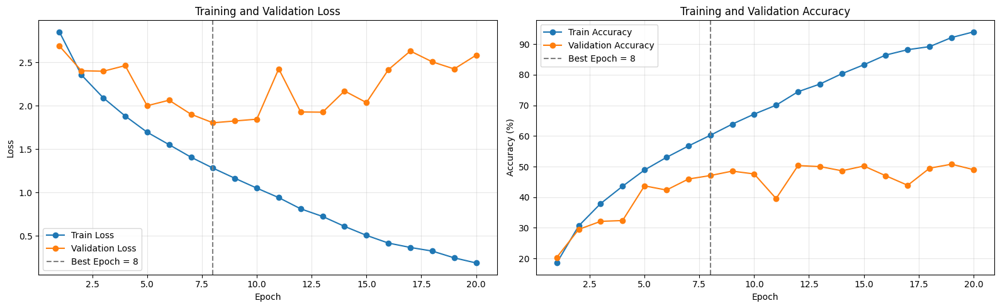

In [ ]:
# Your graph
epochs = range(1, CNN_NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(epochs, cnn_history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs, cnn_history["valid_loss"], marker="o", label="Validation Loss")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {best_epoch}")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, cnn_history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(epochs, cnn_history["valid_acc"], marker="o", label="Validation Accuracy")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {best_epoch}")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

The CNN model contains **1,406,078 trainable parameters**. During training, the training accuracy increased substantially, reaching **94.00%** by epoch 20, while the validation accuracy remained around **49.00%** at the final epoch. The best validation loss was obtained at **epoch 8**, with a validation loss of **1.8052** and validation accuracy of **47.07%**.

This shows that the CNN is able to learn useful features from the training set, but the increasing gap between training and validation performance suggests overfitting. The model fits the training data increasingly well, while its generalisation to unseen validation images is more limited.

CNNs are appropriate for image classification because convolutional layers exploit spatial structure in images. They share weights across locations and learn local visual patterns such as edges, textures and object parts. Compared with an MLP, a CNN requires fewer parameters for image inputs and is more robust to spatial patterns. An MLP would flatten the image and lose much of the spatial structure, making it less efficient and more prone to overfitting on image data.

### 2.2 Generating confusion matrix and ROC curves (6 marks)
- Use your CNN architecture with best accuracy to generate two confusion matrices, one for the training set and another for the validation set. Remember to use the whole validation and training sets, and to include all your relevant code. Display the confusion matrices in a meaningful way which clearly indicates what percentage of the data is represented in each position.
- Display an ROC curve for the two top and two bottom classes with area under the curve

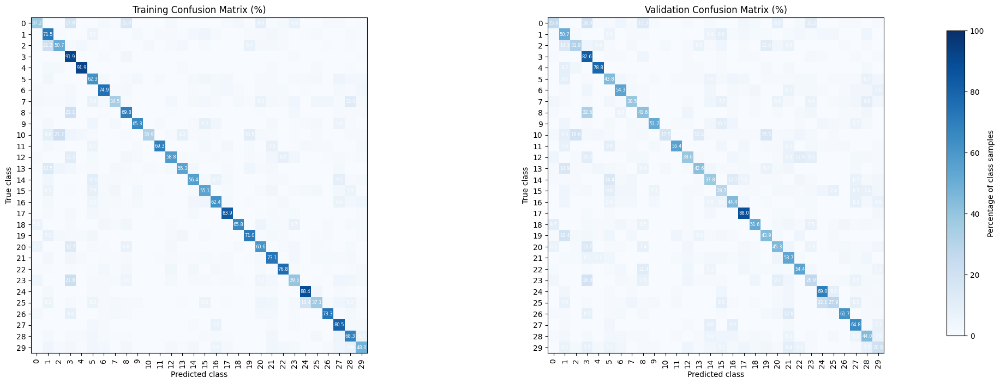

Top 2 validation classes:
Class 17 (jellyfish): 87.95%
Class 3 (bison): 82.61%
Bottom 2 validation classes:
Class 10 (fly): 17.53%
Class 29 (umbrella): 20.83%


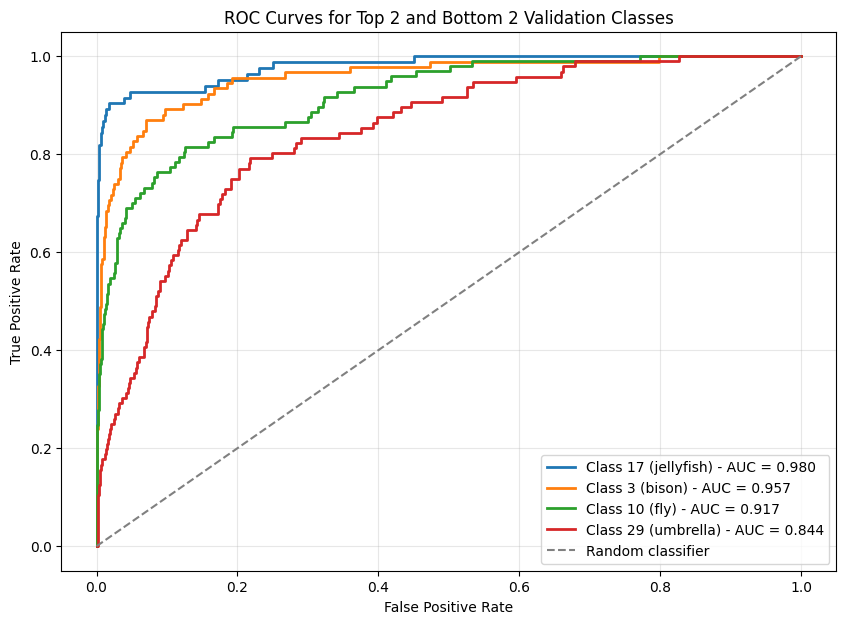

In [ ]:
# Your code here!
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

model.eval()

def collect_predictions_and_scores(model, data_loader, device):
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.concatenate(all_probs, axis=0)
    return all_labels, all_preds, all_probs

train_true, train_pred, train_prob = collect_predictions_and_scores(model, train_loader, device)
valid_true, valid_pred, valid_prob = collect_predictions_and_scores(model, valid_loader, device)

num_classes = len(class_to_idx)
class_indices = np.arange(num_classes)
class_names = [idx_to_class[idx] if idx in idx_to_class else str(idx) for idx in class_indices]

train_cm = confusion_matrix(train_true, train_pred, labels=class_indices)
valid_cm = confusion_matrix(valid_true, valid_pred, labels=class_indices)

train_cm_percent = train_cm.astype(np.float64) / np.maximum(train_cm.sum(axis=1, keepdims=True), 1) * 100.0
valid_cm_percent = valid_cm.astype(np.float64) / np.maximum(valid_cm.sum(axis=1, keepdims=True), 1) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(22, 8))

im0 = axes[0].imshow(train_cm_percent, cmap="Blues", vmin=0, vmax=100)
axes[0].set_title("Training Confusion Matrix (%)")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("True class")
axes[0].set_xticks(class_indices)
axes[0].set_yticks(class_indices)
axes[0].set_xticklabels(class_indices, rotation=90)
axes[0].set_yticklabels(class_indices)

im1 = axes[1].imshow(valid_cm_percent, cmap="Blues", vmin=0, vmax=100)
axes[1].set_title("Validation Confusion Matrix (%)")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")
axes[1].set_xticks(class_indices)
axes[1].set_yticks(class_indices)
axes[1].set_xticklabels(class_indices, rotation=90)
axes[1].set_yticklabels(class_indices)

for ax, cm_percent in zip(axes, [train_cm_percent, valid_cm_percent]):
    for i in range(num_classes):
        for j in range(num_classes):
            value = cm_percent[i, j]
            if value >= 5:
                ax.text(j, i, f"{value:.1f}", ha="center", va="center", color="white", fontsize=6)

fig.subplots_adjust(wspace=0.25, right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(im1, cax=cbar_ax)
cbar.set_label("Percentage of class samples")

plt.show()

valid_class_totals = valid_cm.sum(axis=1)
valid_class_correct = np.diag(valid_cm)
valid_class_accuracy = valid_class_correct / np.maximum(valid_class_totals, 1)

sorted_class_indices = np.argsort(valid_class_accuracy)
bottom_2_classes = sorted_class_indices[:2].tolist()
top_2_classes = sorted_class_indices[-2:][::-1].tolist()
roc_classes = top_2_classes + bottom_2_classes

print("Top 2 validation classes:")
for class_idx in top_2_classes:
    print(f"Class {class_idx} ({class_names[class_idx]}): {valid_class_accuracy[class_idx] * 100:.2f}%")

print("Bottom 2 validation classes:")
for class_idx in bottom_2_classes:
    print(f"Class {class_idx} ({class_names[class_idx]}): {valid_class_accuracy[class_idx] * 100:.2f}%")

valid_true_bin = label_binarize(valid_true, classes=class_indices)

plt.figure(figsize=(10, 7))
for class_idx in roc_classes:
    fpr, tpr, _ = roc_curve(valid_true_bin[:, class_idx], valid_prob[:, class_idx])
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"Class {class_idx} ({class_names[class_idx]}) - AUC = {roc_auc:.3f}"
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.title("ROC Curves for Top 2 and Bottom 2 Validation Classes")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.show()

### 2.3 Strategies for tackling overfitting (12 marks)
Using your (final) CNN model perform the strategies below to avoid overfitting problems. You can reuse the network weights from previous training, often referred to as ``fine tuning``.
*   **2.3.1** Data augmentation
*   **2.3.2** Dropout
*   **2.3.3** Hyperparameter tuning (e.g. changing learning rate)

> Plot loss and accuracy graphs per epoch side by side for each implemented strategy.

#### 2.3.1 Data augmentation (4 marks)

> Implement at least five different data augmentation techniques that should include both photometric and geometric augmentations.

> Provide graphs and comment on what you observe.


Augmentation Epoch [1/10] | Train Loss: 1.4035 | Train Acc: 57.49% | Valid Loss: 1.7781 | Valid Acc: 48.70% | LR: 0.000700
Augmentation Epoch [2/10] | Train Loss: 1.3185 | Train Acc: 59.84% | Valid Loss: 1.6239 | Valid Acc: 53.15% | LR: 0.000700
Augmentation Epoch [3/10] | Train Loss: 1.2422 | Train Acc: 62.35% | Valid Loss: 1.8126 | Valid Acc: 50.56% | LR: 0.000700
Augmentation Epoch [4/10] | Train Loss: 1.2028 | Train Acc: 63.22% | Valid Loss: 1.6497 | Valid Acc: 52.44% | LR: 0.000700
Augmentation Epoch [5/10] | Train Loss: 1.1513 | Train Acc: 64.27% | Valid Loss: 1.6923 | Valid Acc: 51.37% | LR: 0.000350
Augmentation Epoch [6/10] | Train Loss: 1.0091 | Train Acc: 69.08% | Valid Loss: 1.5141 | Valid Acc: 57.78% | LR: 0.000350
Augmentation Epoch [7/10] | Train Loss: 0.9689 | Train Acc: 69.96% | Valid Loss: 1.5172 | Valid Acc: 56.89% | LR: 0.000350
Augmentation Epoch [8/10] | Train Loss: 0.9287 | Train Acc: 70.90% | Valid Loss: 1.4686 | Valid Acc: 57.30% | LR: 0.000350
Augmentation Epo

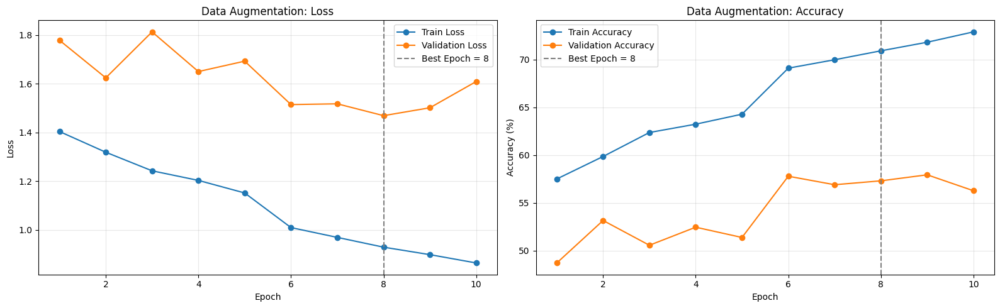

In [ ]:
# Your code here!
import copy

# Data augmentation for training only: moderate geometric + photometric transforms
augmented_train_transform = transforms.Compose([
    transforms.RandomCrop((64, 64), padding=2, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(6),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.98, 1.02), shear=3),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.08, hue=0.02),
    transforms.RandomAutocontrast(p=0.1),
    transforms.RandomAdjustSharpness(sharpness_factor=1.1, p=0.1),
    transforms.ToTensor(),
])

augmented_train_dataset = TinyImageNet30Dataset(
    samples=train_dataset.samples,
    class_to_idx=class_to_idx,
    transform=augmented_train_transform,
)

augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    generator=torch.Generator().manual_seed(SPLIT_SEED),
)

augmentation_num_epochs = 10
augmentation_learning_rate = 7e-4
augmentation_model = TinyImageNetCNN(num_classes=30).to(device)
augmentation_model.load_state_dict(copy.deepcopy(best_model_state))
augmentation_criterion = nn.CrossEntropyLoss()
augmentation_optimizer = torch.optim.Adam(
    augmentation_model.parameters(),
    lr=augmentation_learning_rate,
    weight_decay=CNN_WEIGHT_DECAY,
)
augmentation_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    augmentation_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

augmentation_history = {
    "train_loss": [],
    "valid_loss": [],
    "train_acc": [],
    "valid_acc": [],
}

augmentation_best_epoch = 0
augmentation_best_valid_loss = float("inf")
augmentation_best_state = copy.deepcopy(augmentation_model.state_dict())

for epoch in range(1, augmentation_num_epochs + 1):
    augmentation_model.train()
    aug_train_loss_sum = 0.0
    aug_train_correct = 0.0
    aug_train_examples = 0

    for images, labels in augmented_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        augmentation_optimizer.zero_grad()
        outputs = augmentation_model(images)
        loss = augmentation_criterion(outputs, labels)
        loss.backward()
        augmentation_optimizer.step()

        batch_size = labels.size(0)
        aug_train_loss_sum += loss.item() * batch_size
        aug_train_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
        aug_train_examples += batch_size

    aug_train_loss = aug_train_loss_sum / aug_train_examples
    aug_train_acc = 100.0 * aug_train_correct / aug_train_examples

    augmentation_model.eval()
    aug_valid_loss_sum = 0.0
    aug_valid_correct = 0.0
    aug_valid_examples = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = augmentation_model(images)
            loss = augmentation_criterion(outputs, labels)

            batch_size = labels.size(0)
            aug_valid_loss_sum += loss.item() * batch_size
            aug_valid_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
            aug_valid_examples += batch_size

    aug_valid_loss = aug_valid_loss_sum / aug_valid_examples
    aug_valid_acc = 100.0 * aug_valid_correct / aug_valid_examples

    augmentation_history["train_loss"].append(aug_train_loss)
    augmentation_history["valid_loss"].append(aug_valid_loss)
    augmentation_history["train_acc"].append(aug_train_acc)
    augmentation_history["valid_acc"].append(aug_valid_acc)

    if aug_valid_loss < augmentation_best_valid_loss:
        augmentation_best_valid_loss = aug_valid_loss
        augmentation_best_epoch = epoch
        augmentation_best_state = copy.deepcopy(augmentation_model.state_dict())

    augmentation_scheduler.step(aug_valid_loss)
    current_lr = augmentation_optimizer.param_groups[0]["lr"]

    print(
        f"Augmentation Epoch [{epoch}/{augmentation_num_epochs}] | "
        f"Train Loss: {aug_train_loss:.4f} | Train Acc: {aug_train_acc:.2f}% | "
        f"Valid Loss: {aug_valid_loss:.4f} | Valid Acc: {aug_valid_acc:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

augmentation_model.load_state_dict(augmentation_best_state)
augmentation_best_valid_acc = augmentation_history["valid_acc"][augmentation_best_epoch - 1]
print(f"Best augmentation epoch: {augmentation_best_epoch}")
print(f"Best augmentation validation loss: {augmentation_best_valid_loss:.4f}")
print(f"Validation accuracy at best augmentation epoch: {augmentation_best_valid_acc:.2f}%")

augmentation_epochs = range(1, augmentation_num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(augmentation_epochs, augmentation_history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(augmentation_epochs, augmentation_history["valid_loss"], marker="o", label="Validation Loss")
axes[0].axvline(augmentation_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {augmentation_best_epoch}")
axes[0].set_title("Data Augmentation: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(augmentation_epochs, augmentation_history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(augmentation_epochs, augmentation_history["valid_acc"], marker="o", label="Validation Accuracy")
axes[1].axvline(augmentation_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {augmentation_best_epoch}")
axes[1].set_title("Data Augmentation: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

The data augmentation model improves generalisation compared with the baseline CNN. The best augmented result occurs at **epoch 8**, with validation loss **1.4686** and validation accuracy **57.30%**. This is better than the baseline model, whose best validation loss was **1.8052** with validation accuracy **47.07%**.

The augmentations include both geometric transformations, such as random crop, horizontal flip, rotation and affine transforms, and photometric transformations, such as colour jitter, autocontrast and sharpness adjustment. These transformations expose the model to more varied versions of the training images, reducing its dependence on exact pixel arrangements.

Overall, augmentation reduces overfitting and improves validation performance. The training accuracy remains lower than the non-augmented baseline, but the validation accuracy is higher, which suggests better generalisation.

#### 2.3.2 Dropout (4 marks)

> Implement dropout in your model.

> Provide graphs and comment on your choice of proportion used.

Dropout Epoch [1/10] | Train Loss: 2.2697 | Train Acc: 34.11% | Valid Loss: 1.9059 | Valid Acc: 46.33%
Dropout Epoch [2/10] | Train Loss: 1.8719 | Train Acc: 45.84% | Valid Loss: 1.8708 | Valid Acc: 45.37%
Dropout Epoch [3/10] | Train Loss: 1.7555 | Train Acc: 48.69% | Valid Loss: 1.9803 | Valid Acc: 43.30%
Dropout Epoch [4/10] | Train Loss: 1.6241 | Train Acc: 51.46% | Valid Loss: 1.7102 | Valid Acc: 49.85%
Dropout Epoch [5/10] | Train Loss: 1.5786 | Train Acc: 54.05% | Valid Loss: 1.7118 | Valid Acc: 50.96%
Dropout Epoch [6/10] | Train Loss: 1.5132 | Train Acc: 55.23% | Valid Loss: 1.8562 | Valid Acc: 47.63%
Dropout Epoch [7/10] | Train Loss: 1.4652 | Train Acc: 56.51% | Valid Loss: 1.9349 | Valid Acc: 47.59%
Dropout Epoch [8/10] | Train Loss: 1.4144 | Train Acc: 58.11% | Valid Loss: 1.6001 | Valid Acc: 54.11%
Dropout Epoch [9/10] | Train Loss: 1.3610 | Train Acc: 60.20% | Valid Loss: 1.7452 | Valid Acc: 51.63%
Dropout Epoch [10/10] | Train Loss: 1.2947 | Train Acc: 61.79% | Valid Lo

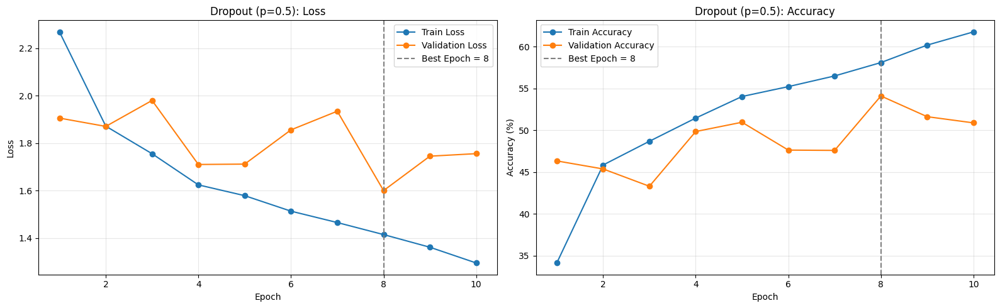

In [ ]:
# Your code here!
import copy

DROPOUT_RATE = 0.5
dropout_num_epochs = 10

class TinyImageNetCNNDropout(nn.Module):
    def __init__(self, num_classes=30, dropout_rate=DROPOUT_RATE):
        super(TinyImageNetCNNDropout, self).__init__()

        def conv_block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 32),
            nn.MaxPool2d(kernel_size=2, stride=2),

            conv_block(32, 64),
            conv_block(64, 64),
            nn.MaxPool2d(kernel_size=2, stride=2),

            conv_block(64, 128),
            conv_block(128, 128),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

dropout_seed = 0
random.seed(dropout_seed)
np.random.seed(dropout_seed)
torch.manual_seed(dropout_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(dropout_seed)

dropout_model = TinyImageNetCNNDropout(num_classes=30, dropout_rate=DROPOUT_RATE).to(device)

# Reuse the trained CNN weights where layer shapes match
dropout_state = dropout_model.state_dict()
for key, value in best_model_state.items():
    if key in dropout_state and dropout_state[key].shape == value.shape:
        dropout_state[key] = value.clone()
dropout_model.load_state_dict(dropout_state)

dropout_criterion = nn.CrossEntropyLoss()
dropout_optimizer = torch.optim.Adam(
    dropout_model.parameters(),
    lr=CNN_LEARNING_RATE,
    weight_decay=CNN_WEIGHT_DECAY,
)

dropout_history = {
    "train_loss": [],
    "valid_loss": [],
    "train_acc": [],
    "valid_acc": [],
}

dropout_best_epoch = 0
dropout_best_valid_loss = float("inf")
dropout_best_state = copy.deepcopy(dropout_model.state_dict())

for epoch in range(1, dropout_num_epochs + 1):
    dropout_model.train()
    dropout_train_loss_sum = 0.0
    dropout_train_correct = 0.0
    dropout_train_examples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        dropout_optimizer.zero_grad()
        outputs = dropout_model(images)
        loss = dropout_criterion(outputs, labels)
        loss.backward()
        dropout_optimizer.step()

        batch_size = labels.size(0)
        dropout_train_loss_sum += loss.item() * batch_size
        dropout_train_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
        dropout_train_examples += batch_size

    dropout_train_loss = dropout_train_loss_sum / dropout_train_examples
    dropout_train_acc = 100.0 * dropout_train_correct / dropout_train_examples

    dropout_model.eval()
    dropout_valid_loss_sum = 0.0
    dropout_valid_correct = 0.0
    dropout_valid_examples = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = dropout_model(images)
            loss = dropout_criterion(outputs, labels)

            batch_size = labels.size(0)
            dropout_valid_loss_sum += loss.item() * batch_size
            dropout_valid_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
            dropout_valid_examples += batch_size

    dropout_valid_loss = dropout_valid_loss_sum / dropout_valid_examples
    dropout_valid_acc = 100.0 * dropout_valid_correct / dropout_valid_examples

    dropout_history["train_loss"].append(dropout_train_loss)
    dropout_history["valid_loss"].append(dropout_valid_loss)
    dropout_history["train_acc"].append(dropout_train_acc)
    dropout_history["valid_acc"].append(dropout_valid_acc)

    if dropout_valid_loss < dropout_best_valid_loss:
        dropout_best_valid_loss = dropout_valid_loss
        dropout_best_epoch = epoch
        dropout_best_state = copy.deepcopy(dropout_model.state_dict())

    print(
        f"Dropout Epoch [{epoch}/{dropout_num_epochs}] | "
        f"Train Loss: {dropout_train_loss:.4f} | Train Acc: {dropout_train_acc:.2f}% | "
        f"Valid Loss: {dropout_valid_loss:.4f} | Valid Acc: {dropout_valid_acc:.2f}%"
    )

dropout_model.load_state_dict(dropout_best_state)
dropout_best_valid_acc = dropout_history["valid_acc"][dropout_best_epoch - 1]
print(f"Dropout rate used: {DROPOUT_RATE}")
print(f"Best dropout epoch: {dropout_best_epoch}")
print(f"Best dropout validation loss: {dropout_best_valid_loss:.4f}")
print(f"Validation accuracy at best dropout epoch: {dropout_best_valid_acc:.2f}%")

dropout_epochs = range(1, dropout_num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(dropout_epochs, dropout_history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(dropout_epochs, dropout_history["valid_loss"], marker="o", label="Validation Loss")
axes[0].axvline(dropout_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {dropout_best_epoch}")
axes[0].set_title(f"Dropout (p={DROPOUT_RATE}): Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(dropout_epochs, dropout_history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(dropout_epochs, dropout_history["valid_acc"], marker="o", label="Validation Accuracy")
axes[1].axvline(dropout_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {dropout_best_epoch}")
axes[1].set_title(f"Dropout (p={DROPOUT_RATE}): Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

The dropout model uses a dropout rate of **0.5**. The best dropout result occurs at **epoch 8**, with validation loss **1.6001** and validation accuracy **54.11%**. This improves over the baseline model, whose best validation accuracy was **47.07%**, although it is slightly weaker than the data augmentation result.

Dropout helps reduce overfitting by randomly deactivating features during training. This prevents the classifier from relying too strongly on a small set of activations and encourages more robust representations. With dropout, the training accuracy is lower than the baseline, but the validation performance improves, which indicates better generalisation.

A dropout proportion of **0.5** is a common regularisation choice for fully connected layers. In this experiment it improves the validation result, but it may also slow training and reduce model capacity, so the final model later uses a slightly lower dropout rate.

#### 2.3.3 Hyperparameter tuning (4 marks)

> Use learning rates [0.1, 0.001, 0.0001].

> Provide graphs each for loss and accuracy at three different learning rates in a single graph.

Learning rate 0.1 | Epoch [1/8] | Train Loss: 19.9126 | Train Acc: 3.72% | Valid Loss: 3.4379 | Valid Acc: 3.19%
Learning rate 0.1 | Epoch [2/8] | Train Loss: 3.4164 | Train Acc: 3.04% | Valid Loss: 3.4234 | Valid Acc: 3.48%
Learning rate 0.1 | Epoch [3/8] | Train Loss: 3.4163 | Train Acc: 3.31% | Valid Loss: 3.4145 | Valid Acc: 3.59%
Learning rate 0.1 | Epoch [4/8] | Train Loss: 3.4163 | Train Acc: 3.31% | Valid Loss: 3.4163 | Valid Acc: 3.22%
Learning rate 0.1 | Epoch [5/8] | Train Loss: 3.4183 | Train Acc: 3.20% | Valid Loss: 3.4203 | Valid Acc: 3.37%
Learning rate 0.1 | Epoch [6/8] | Train Loss: 3.4197 | Train Acc: 3.20% | Valid Loss: 3.4072 | Valid Acc: 3.44%
Learning rate 0.1 | Epoch [7/8] | Train Loss: 3.4175 | Train Acc: 3.18% | Valid Loss: 3.4108 | Valid Acc: 3.63%
Learning rate 0.1 | Epoch [8/8] | Train Loss: 3.4178 | Train Acc: 3.07% | Valid Loss: 3.4232 | Valid Acc: 3.04%
Best result for learning rate 0.1: epoch 6, validation loss = 3.4072, validation accuracy = 3.44%
Learn

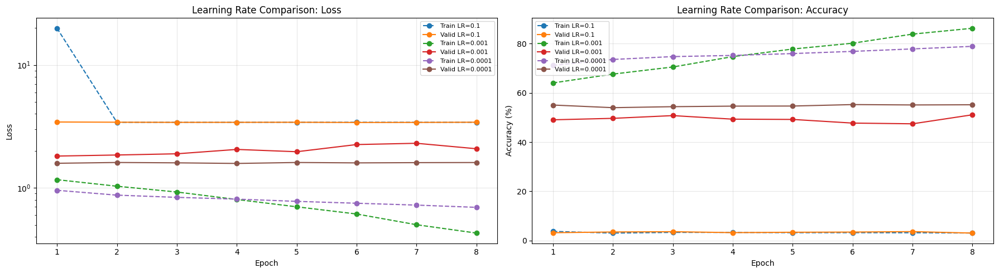

In [ ]:
# Your code here!
import copy

learning_rates = [0.1, 0.001, 0.0001]
lr_num_epochs = 8
lr_histories = {}
lr_best_summary = {}
lr_best_states = {}

for lr in learning_rates:
    lr_model = TinyImageNetCNN(num_classes=30).to(device)
    lr_model.load_state_dict(copy.deepcopy(best_model_state))

    lr_criterion = nn.CrossEntropyLoss()
    lr_optimizer = torch.optim.Adam(
        lr_model.parameters(),
        lr=lr,
        weight_decay=CNN_WEIGHT_DECAY,
    )

    lr_history = {
        "train_loss": [],
        "valid_loss": [],
        "train_acc": [],
        "valid_acc": [],
    }

    best_lr_epoch = 0
    best_lr_valid_loss = float("inf")
    best_lr_state = copy.deepcopy(lr_model.state_dict())

    for epoch in range(1, lr_num_epochs + 1):
        lr_model.train()
        lr_train_loss_sum = 0.0
        lr_train_correct = 0.0
        lr_train_examples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            lr_optimizer.zero_grad()
            outputs = lr_model(images)
            loss = lr_criterion(outputs, labels)
            loss.backward()
            lr_optimizer.step()

            batch_size = labels.size(0)
            lr_train_loss_sum += loss.item() * batch_size
            lr_train_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
            lr_train_examples += batch_size

        lr_train_loss = lr_train_loss_sum / lr_train_examples
        lr_train_acc = 100.0 * lr_train_correct / lr_train_examples

        lr_model.eval()
        lr_valid_loss_sum = 0.0
        lr_valid_correct = 0.0
        lr_valid_examples = 0

        with torch.no_grad():
            for images, labels in valid_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = lr_model(images)
                loss = lr_criterion(outputs, labels)

                batch_size = labels.size(0)
                lr_valid_loss_sum += loss.item() * batch_size
                lr_valid_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
                lr_valid_examples += batch_size

        lr_valid_loss = lr_valid_loss_sum / lr_valid_examples
        lr_valid_acc = 100.0 * lr_valid_correct / lr_valid_examples

        lr_history["train_loss"].append(lr_train_loss)
        lr_history["valid_loss"].append(lr_valid_loss)
        lr_history["train_acc"].append(lr_train_acc)
        lr_history["valid_acc"].append(lr_valid_acc)

        if lr_valid_loss < best_lr_valid_loss:
            best_lr_valid_loss = lr_valid_loss
            best_lr_epoch = epoch
            best_lr_state = copy.deepcopy(lr_model.state_dict())

        print(
            f"Learning rate {lr} | Epoch [{epoch}/{lr_num_epochs}] | "
            f"Train Loss: {lr_train_loss:.4f} | Train Acc: {lr_train_acc:.2f}% | "
            f"Valid Loss: {lr_valid_loss:.4f} | Valid Acc: {lr_valid_acc:.2f}%"
        )

    lr_histories[lr] = lr_history
    lr_best_summary[lr] = {
        "best_epoch": best_lr_epoch,
        "best_valid_loss": best_lr_valid_loss,
        "best_valid_acc": lr_history["valid_acc"][best_lr_epoch - 1],
    }
    lr_best_states[lr] = best_lr_state

    print(
        f"Best result for learning rate {lr}: "
        f"epoch {best_lr_epoch}, validation loss = {best_lr_valid_loss:.4f}, "
        f"validation accuracy = {lr_best_summary[lr]['best_valid_acc']:.2f}%"
    )

lr_epochs = range(1, lr_num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

for lr in learning_rates:
    axes[0].plot(lr_epochs, lr_histories[lr]["train_loss"], linestyle="--", marker="o", label=f"Train LR={lr}")
    axes[0].plot(lr_epochs, lr_histories[lr]["valid_loss"], linestyle="-", marker="o", label=f"Valid LR={lr}")

axes[0].set_title("Learning Rate Comparison: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

for lr in learning_rates:
    axes[1].plot(lr_epochs, lr_histories[lr]["train_acc"], linestyle="--", marker="o", label=f"Train LR={lr}")
    axes[1].plot(lr_epochs, lr_histories[lr]["valid_acc"], linestyle="-", marker="o", label=f"Valid LR={lr}")

axes[1].set_title("Learning Rate Comparison: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

The learning-rate experiment shows that the optimisation is highly sensitive to the learning rate.

For **learning rate = 0.1**, training is unstable. The first epoch has a very large training loss, and the validation accuracy remains close to random guessing for a 30-class classification problem. The best validation accuracy is only **3.44%**, so this learning rate is too large.

For **learning rate = 0.001**, the model learns the training data quickly, but validation loss increases and the validation accuracy does not improve sufficiently. The best validation loss is **1.8157** at epoch 1, with validation accuracy **49.07%**, suggesting overfitting during continued training.

For **learning rate = 0.0001**, training is more stable. The best validation loss is **1.5810** at epoch 4, with validation accuracy **54.63%**. This is the best and most stable of the three learning rates, so it is selected for the final model.

In [ ]:
# Select and save the final Section 2 model before Section 3
import os
import copy

FINAL_MODEL_SEED = 0
random.seed(FINAL_MODEL_SEED)
np.random.seed(FINAL_MODEL_SEED)
torch.manual_seed(FINAL_MODEL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(FINAL_MODEL_SEED)

best_lr_key = min(
    lr_best_summary,
    key=lambda lr: (lr_best_summary[lr]["best_valid_loss"], -lr_best_summary[lr]["best_valid_acc"], lr_best_summary[lr]["best_epoch"])
)

FINAL_MODEL_NUM_EPOCHS = 15
FINAL_MODEL_DROPOUT_RATE = min(DROPOUT_RATE, 0.4)
FINAL_MODEL_WEIGHT_DECAY = 1e-4
FINAL_MODEL_LEARNING_RATE = float(best_lr_key)
FINAL_LOSS_TIE_TOLERANCE = 1e-4

final_model = TinyImageNetCNNDropout(num_classes=30, dropout_rate=FINAL_MODEL_DROPOUT_RATE).to(device)
final_model_state = final_model.state_dict()
for key, value in best_model_state.items():
    if key in final_model_state and final_model_state[key].shape == value.shape:
        final_model_state[key] = value.clone()
final_model.load_state_dict(final_model_state)

final_criterion = nn.CrossEntropyLoss()
final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=FINAL_MODEL_LEARNING_RATE,
    weight_decay=FINAL_MODEL_WEIGHT_DECAY,
)

final_history = {
    "train_loss": [],
    "valid_loss": [],
    "train_acc": [],
    "valid_acc": [],
}

final_best_epoch = 0
final_best_valid_loss = float("inf")
final_best_valid_acc = 0.0
final_best_state = copy.deepcopy(final_model.state_dict())

for epoch in range(1, FINAL_MODEL_NUM_EPOCHS + 1):
    final_model.train()
    train_loss_sum = 0.0
    train_correct = 0.0
    train_examples = 0

    for images, labels in augmented_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        final_optimizer.zero_grad()
        outputs = final_model(images)
        loss = final_criterion(outputs, labels)
        loss.backward()
        final_optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
        train_examples += batch_size

    train_loss = train_loss_sum / train_examples
    train_acc = 100.0 * train_correct / train_examples

    final_model.eval()
    valid_loss_sum = 0.0
    valid_correct = 0.0
    valid_examples = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = final_model(images)
            loss = final_criterion(outputs, labels)

            batch_size = labels.size(0)
            valid_loss_sum += loss.item() * batch_size
            valid_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
            valid_examples += batch_size

    valid_loss = valid_loss_sum / valid_examples
    valid_acc = 100.0 * valid_correct / valid_examples

    final_history["train_loss"].append(train_loss)
    final_history["valid_loss"].append(valid_loss)
    final_history["train_acc"].append(train_acc)
    final_history["valid_acc"].append(valid_acc)

    is_better_checkpoint = False
    if valid_loss < final_best_valid_loss - FINAL_LOSS_TIE_TOLERANCE:
        is_better_checkpoint = True
    elif abs(valid_loss - final_best_valid_loss) <= FINAL_LOSS_TIE_TOLERANCE:
        if valid_acc > final_best_valid_acc + 1e-6:
            is_better_checkpoint = True
        elif abs(valid_acc - final_best_valid_acc) <= 1e-6 and (final_best_epoch == 0 or epoch < final_best_epoch):
            is_better_checkpoint = True

    if is_better_checkpoint:
        final_best_valid_loss = valid_loss
        final_best_valid_acc = valid_acc
        final_best_epoch = epoch
        final_best_state = copy.deepcopy(final_model.state_dict())

    print(
        f"Final Model Epoch [{epoch}/{FINAL_MODEL_NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
        f"Valid Loss: {valid_loss:.4f} | Valid Acc: {valid_acc:.2f}%"
    )

final_model.load_state_dict(final_best_state)

print("\nFinal model training summary:")
print(f"Learning rate selected from Section 2.3.3: {FINAL_MODEL_LEARNING_RATE}")
print(f"Dropout rate used: {FINAL_MODEL_DROPOUT_RATE}")
print(f"Weight decay used: {FINAL_MODEL_WEIGHT_DECAY}")
print(f"Best epoch: {final_best_epoch}")
print(f"Best validation loss: {final_best_valid_loss:.4f}")
print(f"Validation accuracy at best epoch: {final_best_valid_acc:.2f}%")

FINAL_MODEL_CHECKPOINT_PATH = "tinyimagenet30_final_model_checkpoint.pt"
torch.save(
    {
        "selected_model_name": "final_dual_regularized_model",
        "model_class": "TinyImageNetCNNDropout",
        "best_epoch": final_best_epoch,
        "best_valid_loss": final_best_valid_loss,
        "best_valid_acc": final_best_valid_acc,
        "selection_rule": "lowest validation loss, then highest validation accuracy, then earlier epoch",
        "training_setup": {
            "augmentation": True,
            "dropout_rate": FINAL_MODEL_DROPOUT_RATE,
            "weight_decay": FINAL_MODEL_WEIGHT_DECAY,
            "learning_rate": FINAL_MODEL_LEARNING_RATE,
            "num_epochs": FINAL_MODEL_NUM_EPOCHS,
            "seed": FINAL_MODEL_SEED,
        },
        "state_dict": final_best_state,
        "class_to_idx": class_to_idx,
        "idx_to_class": idx_to_class,
    },
    FINAL_MODEL_CHECKPOINT_PATH,
)

print(f"Final model checkpoint saved to: {os.path.abspath(FINAL_MODEL_CHECKPOINT_PATH)}")


Final Model Epoch [1/15] | Train Loss: 2.7043 | Train Acc: 23.72% | Valid Loss: 2.1317 | Valid Acc: 45.00%
Final Model Epoch [2/15] | Train Loss: 2.2541 | Train Acc: 34.90% | Valid Loss: 1.8675 | Valid Acc: 48.78%
Final Model Epoch [3/15] | Train Loss: 2.0775 | Train Acc: 39.17% | Valid Loss: 1.7318 | Valid Acc: 51.04%
Final Model Epoch [4/15] | Train Loss: 1.9636 | Train Acc: 42.15% | Valid Loss: 1.6749 | Valid Acc: 51.70%
Final Model Epoch [5/15] | Train Loss: 1.8716 | Train Acc: 45.69% | Valid Loss: 1.6328 | Valid Acc: 52.67%
Final Model Epoch [6/15] | Train Loss: 1.8008 | Train Acc: 46.91% | Valid Loss: 1.5945 | Valid Acc: 53.44%
Final Model Epoch [7/15] | Train Loss: 1.7633 | Train Acc: 48.10% | Valid Loss: 1.5671 | Valid Acc: 53.59%
Final Model Epoch [8/15] | Train Loss: 1.6997 | Train Acc: 50.01% | Valid Loss: 1.5304 | Valid Acc: 54.96%
Final Model Epoch [9/15] | Train Loss: 1.6729 | Train Acc: 50.99% | Valid Loss: 1.5311 | Valid Acc: 54.96%
Final Model Epoch [10/15] | Train Los

### 3 Model testing [10 marks]
Online evaluation of your model performance on the test set.

> Prepare the dataloader for the testset.

> Write evaluation code for writing predictions.

> Upload it to Kaggle submission page (6 marks).


#### 3.1 Test class and predictions (4 marks)

> Build a test class, prepare a test dataloader and generate predictions.

Create a PyTorch ```Dataset``` for the unlabeled test data in the test_set folder of the Kaggle competition and generate predictions using your final model. Test data can be downloaded [here](https://www.kaggle.com/competitions/comp5623m-artificial-intelligence/data?select=test_set).

In [ ]:
# Your code here!
import os
import pandas as pd
from pathlib import Path

FINAL_MODEL_CHECKPOINT_PATH = "tinyimagenet30_final_model_checkpoint.pt"
final_checkpoint = torch.load(FINAL_MODEL_CHECKPOINT_PATH, map_location=device)

selected_final_model_name = final_checkpoint["selected_model_name"]
selected_final_model_class = final_checkpoint["model_class"]

print(f"Using final model for Section 3.1: {selected_final_model_name}")
print(f"Loaded from checkpoint: {os.path.abspath(FINAL_MODEL_CHECKPOINT_PATH)}")

if selected_final_model_class == "TinyImageNetCNN":
    final_test_model = TinyImageNetCNN(num_classes=30).to(device)
elif selected_final_model_class == "TinyImageNetCNNDropout":
    final_test_model = TinyImageNetCNNDropout(num_classes=30, dropout_rate=DROPOUT_RATE).to(device)
else:
    raise ValueError(f"Unsupported model class in checkpoint: {selected_final_model_class}")

final_test_model.load_state_dict(final_checkpoint["state_dict"])
final_test_model.eval()

TEST_SET_ROOT = "tinyimagenet30/test_set"
TEST_BATCH_SIZE = BATCH_SIZE

def resolve_tinyimagenet30_test_root(root_dir):
    current_dir = Path(root_dir).resolve()

    while True:
        if not current_dir.exists():
            raise FileNotFoundError(f"Test directory not found: {current_dir}")

        image_files = sorted([
            file_path for file_path in current_dir.iterdir()
            if file_path.is_file() and file_path.suffix in IMG_EXTENSIONS
        ])
        if image_files:
            return current_dir

        subdirs = sorted([path for path in current_dir.iterdir() if path.is_dir()])
        if len(subdirs) == 1:
            current_dir = subdirs[0]
        else:
            raise ValueError(f"Could not locate test images under: {Path(root_dir).resolve()}")

class TinyImageNet30TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = resolve_tinyimagenet30_test_root(root_dir)
        self.transform = transform
        self.image_paths = sorted([
            file_path for file_path in self.root_dir.iterdir()
            if file_path.is_file() and file_path.suffix in IMG_EXTENSIONS
        ], key=lambda path: path.name)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        image = Image.open(image_path).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, image_path.name

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

test_dataset = TinyImageNet30TestDataset(TEST_SET_ROOT, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=TEST_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

test_predictions = []
with torch.no_grad():
    for images, file_names in test_loader:
        images = images.to(device)
        outputs = final_test_model(images)
        predicted_labels = outputs.argmax(dim=1).cpu().numpy()

        for file_name, predicted_label in zip(file_names, predicted_labels):
            test_predictions.append({
                "Id": file_name,
                "Category": int(predicted_label),
            })

test_predictions_df = pd.DataFrame(test_predictions)

print(f"Number of test images: {len(test_dataset)}")
print(f"Number of predictions generated: {len(test_predictions_df)}")
display(test_predictions_df.head())

Using final model for Section 3.1: final_dual_regularized_model
Loaded from checkpoint: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/tinyimagenet30_final_model_checkpoint.pt
Number of test images: 1500
Number of predictions generated: 1500


,Id,Category
0,003e8ac5_d95f.JPEG,19
1,00cc0f59_c28c.JPEG,8
2,012f1624_cf5f.JPEG,19
3,013b6458_ebee.JPEG,15
4,016330f6_4c40.JPEG,16


#### 3.2 Prepare your submission and upload to Kaggle  (6 marks)

Save all test predictions to a CSV file and submit it to the private class Kaggle competition. **Please save your test CSV file submissions using your student username (the one with letters, e.g., ``sc15jb``, not the ID with only numbers)**, for example, `sc15jb.csv`. That will help us to identify your submissions.

The CSV file must contain only two columns: ‘Id’ and ‘Category’ (predicted class ID) as shown below:

```txt
Id,Category
28d0f5e9_373c.JPEG,2
bbe4895f_40bf.JPEG,18
```

The ‘Id’ column should include the name of the image. It is important to keep the same name as the one on the test set. Do not include any path, just the name of file (with extension). Your csv file must contain 1501 rows, one for each image in test set and 1 row for the headers. [To submit please click here.](https://www.kaggle.com/t/917fe52f6a3c4855880a24b34f26db07)

> You may submit multiple times. We will use your personal top entry for allocating marks for this [6 marks].


In [ ]:
# Your code here!
SUBMISSION_USERNAME = "nplw0197"  # Replace this with your student username before final submission
SUBMISSION_FILENAME = f"{SUBMISSION_USERNAME}.csv"

submission_df = test_predictions_df[["Id", "Category"]].copy()
submission_df["Id"] = submission_df["Id"].astype(str).apply(os.path.basename)
submission_df["Category"] = submission_df["Category"].astype(int)

assert list(submission_df.columns) == ["Id", "Category"], "Submission must contain exactly two columns: Id and Category"
assert submission_df["Id"].str.contains(r"[/\\]").sum() == 0, "Id column must contain filenames only, without paths"
assert len(submission_df) == len(test_predictions_df), "Submission row count does not match number of test predictions"

submission_df.to_csv(SUBMISSION_FILENAME, index=False)

print(f"Submission CSV saved to: {os.path.abspath(SUBMISSION_FILENAME)}")
print(f"Submission shape: {submission_df.shape}")
display(submission_df.head())

Submission CSV saved to: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/nplw0197.csv
Submission shape: (1500, 2)


,Id,Category
0,003e8ac5_d95f.JPEG,19
1,00cc0f59_c28c.JPEG,8
2,012f1624_cf5f.JPEG,19
3,013b6458_ebee.JPEG,15
4,016330f6_4c40.JPEG,16



### 4 Model Fine-tuning/transfer learning on CIFAR10 dataset  [16 marks]

Fine-tuning is a way of applying or utilizing transfer learning. It is a process that takes a model that has already been trained for one given task and then tunes or tweaks the model to make it perform a second similar task. You can perform fine-tuning in the following fashion:

- Train an entire model: Start training model from scratch (large dataset, more computation)

- Train some layers, freeze others: Lower layer features are general (problem independent) while higher layer features are specific (problem dependent – freeze)

- Freeze convolution base and train only last FC layers (small dataset and lower computation)

> **Configuring your dataset**
   - Download your dataset using ``torchvision.datasets.CIFAR10`` [explained here](https://pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html)
   - Split training dataset into training and validation set similar to above. *Note that the number of categories here is only 10*


In [ ]:
# Your code here!
from torchvision.datasets import CIFAR10
from torch.utils.data import random_split

CIFAR10_ROOT = "./cifar10_data"
CIFAR10_VALID_RATIO = 0.2
CIFAR10_SPLIT_SEED = 0
CIFAR10_BATCH_SIZE = BATCH_SIZE

cifar10_train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

cifar10_valid_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

cifar10_full_train_dataset = CIFAR10(
    root=CIFAR10_ROOT,
    train=True,
    transform=cifar10_train_transform,
    download=True,
)

cifar10_valid_dataset_full = CIFAR10(
    root=CIFAR10_ROOT,
    train=True,
    transform=cifar10_valid_transform,
    download=False,
)

cifar10_total_size = len(cifar10_full_train_dataset)
cifar10_valid_size = int(cifar10_total_size * CIFAR10_VALID_RATIO)
cifar10_train_size = cifar10_total_size - cifar10_valid_size

cifar10_generator = torch.Generator().manual_seed(CIFAR10_SPLIT_SEED)
cifar10_train_dataset, cifar10_valid_dataset = random_split(
    cifar10_full_train_dataset,
    [cifar10_train_size, cifar10_valid_size],
    generator=cifar10_generator,
)

# Rebuild the validation subset so it uses validation transforms only
cifar10_valid_indices = cifar10_valid_dataset.indices
cifar10_valid_dataset = torch.utils.data.Subset(cifar10_valid_dataset_full, cifar10_valid_indices)

cifar10_train_loader = DataLoader(
    cifar10_train_dataset,
    batch_size=CIFAR10_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

cifar10_valid_loader = DataLoader(
    cifar10_valid_dataset,
    batch_size=CIFAR10_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print(f"CIFAR10 train samples: {len(cifar10_train_dataset)}")
print(f"CIFAR10 validation samples: {len(cifar10_valid_dataset)}")
print(f"CIFAR10 batch size: {CIFAR10_BATCH_SIZE}")

100%|██████████| 170M/170M [01:16<00:00, 2.23MB/s]


CIFAR10 train samples: 40000
CIFAR10 validation samples: 10000
CIFAR10 batch size: 64


> Load pretrained AlexNet from PyTorch - use model copies to apply transfer learning in different configurations

In [ ]:
# Your code here!
from torchvision.models import alexnet, AlexNet_Weights

alexnet_model = alexnet(weights=AlexNet_Weights.DEFAULT)
alexnet_model.classifier[6] = nn.Linear(alexnet_model.classifier[6].in_features, 10)
alexnet_model = alexnet_model.to(device)

print(alexnet_model)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 182MB/s]


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

#### 4.1 Apply transfer learning with pretrained model weights (6 marks)


> Configuration 1: No frozen layers

Total parameters: 57,044,810
Trainable parameters: 57,044,810
AlexNet Full FT Epoch [1/8] | Train Loss: 0.9722 | Train Acc: 65.63% | Valid Loss: 0.7597 | Valid Acc: 73.62%
AlexNet Full FT Epoch [2/8] | Train Loss: 0.6459 | Train Acc: 77.28% | Valid Loss: 0.7059 | Valid Acc: 75.53%
AlexNet Full FT Epoch [3/8] | Train Loss: 0.4943 | Train Acc: 82.70% | Valid Loss: 0.6426 | Valid Acc: 78.21%
AlexNet Full FT Epoch [4/8] | Train Loss: 0.3742 | Train Acc: 86.71% | Valid Loss: 0.6683 | Valid Acc: 78.33%
AlexNet Full FT Epoch [5/8] | Train Loss: 0.2748 | Train Acc: 90.27% | Valid Loss: 0.7094 | Valid Acc: 79.24%
AlexNet Full FT Epoch [6/8] | Train Loss: 0.1995 | Train Acc: 92.92% | Valid Loss: 0.8080 | Valid Acc: 77.71%
AlexNet Full FT Epoch [7/8] | Train Loss: 0.1530 | Train Acc: 94.52% | Valid Loss: 0.8472 | Valid Acc: 78.94%
AlexNet Full FT Epoch [8/8] | Train Loss: 0.1239 | Train Acc: 95.64% | Valid Loss: 0.8605 | Valid Acc: 79.14%
Best epoch: 3
Best validation loss: 0.6426
Validation accu

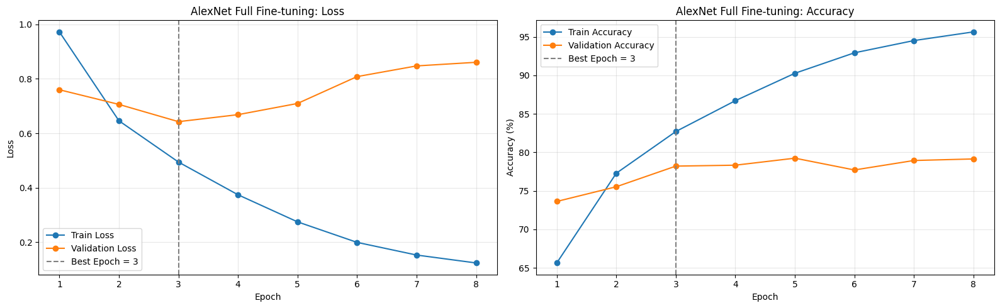

In [ ]:
# Your model changes here - also print trainable parameters
alexnet_full_ft_model = alexnet_model.to(device)
for param in alexnet_full_ft_model.parameters():
    param.requires_grad = True

alexnet_full_total_params = sum(p.numel() for p in alexnet_full_ft_model.parameters())
alexnet_full_trainable_params = sum(p.numel() for p in alexnet_full_ft_model.parameters() if p.requires_grad)

print(f"Total parameters: {alexnet_full_total_params:,}")
print(f"Trainable parameters: {alexnet_full_trainable_params:,}")

alexnet_full_num_epochs = 8
alexnet_full_criterion = nn.CrossEntropyLoss()
alexnet_full_optimizer = torch.optim.Adam(alexnet_full_ft_model.parameters(), lr=1e-4)

alexnet_full_history = {
    "train_loss": [],
    "valid_loss": [],
    "train_acc": [],
    "valid_acc": [],
}

alexnet_full_best_epoch = 0
alexnet_full_best_valid_loss = float("inf")
alexnet_full_best_state = copy.deepcopy(alexnet_full_ft_model.state_dict())

for epoch in range(1, alexnet_full_num_epochs + 1):
    alexnet_full_ft_model.train()
    alexnet_full_train_loss_sum = 0.0
    alexnet_full_train_correct = 0.0
    alexnet_full_train_examples = 0

    for images, labels in cifar10_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        alexnet_full_optimizer.zero_grad()
        outputs = alexnet_full_ft_model(images)
        loss = alexnet_full_criterion(outputs, labels)
        loss.backward()
        alexnet_full_optimizer.step()

        batch_size = labels.size(0)
        alexnet_full_train_loss_sum += loss.item() * batch_size
        alexnet_full_train_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
        alexnet_full_train_examples += batch_size

    alexnet_full_train_loss = alexnet_full_train_loss_sum / alexnet_full_train_examples
    alexnet_full_train_acc = 100.0 * alexnet_full_train_correct / alexnet_full_train_examples

    alexnet_full_ft_model.eval()
    alexnet_full_valid_loss_sum = 0.0
    alexnet_full_valid_correct = 0.0
    alexnet_full_valid_examples = 0

    with torch.no_grad():
        for images, labels in cifar10_valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = alexnet_full_ft_model(images)
            loss = alexnet_full_criterion(outputs, labels)

            batch_size = labels.size(0)
            alexnet_full_valid_loss_sum += loss.item() * batch_size
            alexnet_full_valid_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
            alexnet_full_valid_examples += batch_size

    alexnet_full_valid_loss = alexnet_full_valid_loss_sum / alexnet_full_valid_examples
    alexnet_full_valid_acc = 100.0 * alexnet_full_valid_correct / alexnet_full_valid_examples

    alexnet_full_history["train_loss"].append(alexnet_full_train_loss)
    alexnet_full_history["valid_loss"].append(alexnet_full_valid_loss)
    alexnet_full_history["train_acc"].append(alexnet_full_train_acc)
    alexnet_full_history["valid_acc"].append(alexnet_full_valid_acc)

    if alexnet_full_valid_loss < alexnet_full_best_valid_loss:
        alexnet_full_best_valid_loss = alexnet_full_valid_loss
        alexnet_full_best_epoch = epoch
        alexnet_full_best_state = copy.deepcopy(alexnet_full_ft_model.state_dict())

    print(
        f"AlexNet Full FT Epoch [{epoch}/{alexnet_full_num_epochs}] | "
        f"Train Loss: {alexnet_full_train_loss:.4f} | Train Acc: {alexnet_full_train_acc:.2f}% | "
        f"Valid Loss: {alexnet_full_valid_loss:.4f} | Valid Acc: {alexnet_full_valid_acc:.2f}%"
    )

alexnet_full_ft_model.load_state_dict(alexnet_full_best_state)
alexnet_full_best_valid_acc = alexnet_full_history["valid_acc"][alexnet_full_best_epoch - 1]
print(f"Best epoch: {alexnet_full_best_epoch}")
print(f"Best validation loss: {alexnet_full_best_valid_loss:.4f}")
print(f"Validation accuracy at best epoch: {alexnet_full_best_valid_acc:.2f}%")

alexnet_full_epochs = range(1, alexnet_full_num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(alexnet_full_epochs, alexnet_full_history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(alexnet_full_epochs, alexnet_full_history["valid_loss"], marker="o", label="Validation Loss")
axes[0].axvline(alexnet_full_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {alexnet_full_best_epoch}")
axes[0].set_title("AlexNet Full Fine-tuning: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(alexnet_full_epochs, alexnet_full_history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(alexnet_full_epochs, alexnet_full_history["valid_acc"], marker="o", label="Validation Accuracy")
axes[1].axvline(alexnet_full_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {alexnet_full_best_epoch}")
axes[1].set_title("AlexNet Full Fine-tuning: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

#### 4.2 Fine-tuning model with frozen layers (6 marks)

> Configuration 2: Frozen base convolution blocks

Total parameters: 57,044,810
Trainable parameters: 54,575,114
AlexNet Frozen Features Epoch [1/8] | Train Loss: 1.3102 | Train Acc: 53.47% | Valid Loss: 1.1484 | Valid Acc: 58.98%
AlexNet Frozen Features Epoch [2/8] | Train Loss: 1.1230 | Train Acc: 60.25% | Valid Loss: 1.0926 | Valid Acc: 61.14%
AlexNet Frozen Features Epoch [3/8] | Train Loss: 1.0508 | Train Acc: 62.91% | Valid Loss: 1.0566 | Valid Acc: 63.27%
AlexNet Frozen Features Epoch [4/8] | Train Loss: 0.9974 | Train Acc: 64.48% | Valid Loss: 1.0391 | Valid Acc: 63.95%
AlexNet Frozen Features Epoch [5/8] | Train Loss: 0.9491 | Train Acc: 66.11% | Valid Loss: 1.0179 | Valid Acc: 64.68%
AlexNet Frozen Features Epoch [6/8] | Train Loss: 0.8985 | Train Acc: 67.94% | Valid Loss: 1.0076 | Valid Acc: 64.89%
AlexNet Frozen Features Epoch [7/8] | Train Loss: 0.8583 | Train Acc: 69.31% | Valid Loss: 1.0169 | Valid Acc: 64.58%
AlexNet Frozen Features Epoch [8/8] | Train Loss: 0.8143 | Train Acc: 71.07% | Valid Loss: 1.0015 | Valid Acc: 6

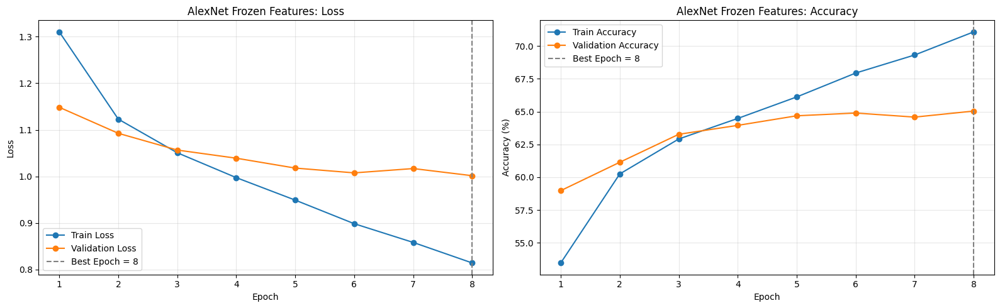

In [ ]:
# Your changes here - also print trainable parameters
alexnet_frozen_model = alexnet(weights=AlexNet_Weights.DEFAULT)
alexnet_frozen_model.classifier[6] = nn.Linear(alexnet_frozen_model.classifier[6].in_features, 10)
alexnet_frozen_model = alexnet_frozen_model.to(device)

for param in alexnet_frozen_model.features.parameters():
    param.requires_grad = False

for param in alexnet_frozen_model.classifier.parameters():
    param.requires_grad = True

alexnet_frozen_total_params = sum(p.numel() for p in alexnet_frozen_model.parameters())
alexnet_frozen_trainable_params = sum(p.numel() for p in alexnet_frozen_model.parameters() if p.requires_grad)

print(f"Total parameters: {alexnet_frozen_total_params:,}")
print(f"Trainable parameters: {alexnet_frozen_trainable_params:,}")

alexnet_frozen_num_epochs = 8
alexnet_frozen_criterion = nn.CrossEntropyLoss()
alexnet_frozen_optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, alexnet_frozen_model.parameters()),
    lr=1e-4,
)

alexnet_frozen_history = {
    "train_loss": [],
    "valid_loss": [],
    "train_acc": [],
    "valid_acc": [],
}

alexnet_frozen_best_epoch = 0
alexnet_frozen_best_valid_loss = float("inf")
alexnet_frozen_best_state = copy.deepcopy(alexnet_frozen_model.state_dict())

for epoch in range(1, alexnet_frozen_num_epochs + 1):
    alexnet_frozen_model.train()
    alexnet_frozen_train_loss_sum = 0.0
    alexnet_frozen_train_correct = 0.0
    alexnet_frozen_train_examples = 0

    for images, labels in cifar10_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        alexnet_frozen_optimizer.zero_grad()
        outputs = alexnet_frozen_model(images)
        loss = alexnet_frozen_criterion(outputs, labels)
        loss.backward()
        alexnet_frozen_optimizer.step()

        batch_size = labels.size(0)
        alexnet_frozen_train_loss_sum += loss.item() * batch_size
        alexnet_frozen_train_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
        alexnet_frozen_train_examples += batch_size

    alexnet_frozen_train_loss = alexnet_frozen_train_loss_sum / alexnet_frozen_train_examples
    alexnet_frozen_train_acc = 100.0 * alexnet_frozen_train_correct / alexnet_frozen_train_examples

    alexnet_frozen_model.eval()
    alexnet_frozen_valid_loss_sum = 0.0
    alexnet_frozen_valid_correct = 0.0
    alexnet_frozen_valid_examples = 0

    with torch.no_grad():
        for images, labels in cifar10_valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = alexnet_frozen_model(images)
            loss = alexnet_frozen_criterion(outputs, labels)

            batch_size = labels.size(0)
            alexnet_frozen_valid_loss_sum += loss.item() * batch_size
            alexnet_frozen_valid_correct += topk_accuracy(outputs, labels, topk=(1,))[0].item() * batch_size / 100.0
            alexnet_frozen_valid_examples += batch_size

    alexnet_frozen_valid_loss = alexnet_frozen_valid_loss_sum / alexnet_frozen_valid_examples
    alexnet_frozen_valid_acc = 100.0 * alexnet_frozen_valid_correct / alexnet_frozen_valid_examples

    alexnet_frozen_history["train_loss"].append(alexnet_frozen_train_loss)
    alexnet_frozen_history["valid_loss"].append(alexnet_frozen_valid_loss)
    alexnet_frozen_history["train_acc"].append(alexnet_frozen_train_acc)
    alexnet_frozen_history["valid_acc"].append(alexnet_frozen_valid_acc)

    if alexnet_frozen_valid_loss < alexnet_frozen_best_valid_loss:
        alexnet_frozen_best_valid_loss = alexnet_frozen_valid_loss
        alexnet_frozen_best_epoch = epoch
        alexnet_frozen_best_state = copy.deepcopy(alexnet_frozen_model.state_dict())

    print(
        f"AlexNet Frozen Features Epoch [{epoch}/{alexnet_frozen_num_epochs}] | "
        f"Train Loss: {alexnet_frozen_train_loss:.4f} | Train Acc: {alexnet_frozen_train_acc:.2f}% | "
        f"Valid Loss: {alexnet_frozen_valid_loss:.4f} | Valid Acc: {alexnet_frozen_valid_acc:.2f}%"
    )

alexnet_frozen_model.load_state_dict(alexnet_frozen_best_state)
alexnet_frozen_best_valid_acc = alexnet_frozen_history["valid_acc"][alexnet_frozen_best_epoch - 1]
print(f"Best epoch: {alexnet_frozen_best_epoch}")
print(f"Best validation loss: {alexnet_frozen_best_valid_loss:.4f}")
print(f"Validation accuracy at best epoch: {alexnet_frozen_best_valid_acc:.2f}%")

alexnet_frozen_epochs = range(1, alexnet_frozen_num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(alexnet_frozen_epochs, alexnet_frozen_history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(alexnet_frozen_epochs, alexnet_frozen_history["valid_loss"], marker="o", label="Validation Loss")
axes[0].axvline(alexnet_frozen_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {alexnet_frozen_best_epoch}")
axes[0].set_title("AlexNet Frozen Features: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(alexnet_frozen_epochs, alexnet_frozen_history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(alexnet_frozen_epochs, alexnet_frozen_history["valid_acc"], marker="o", label="Validation Accuracy")
axes[1].axvline(alexnet_frozen_best_epoch, color="gray", linestyle="--", label=f"Best Epoch = {alexnet_frozen_best_epoch}")
axes[1].set_title("AlexNet Frozen Features: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

#### 4.3 Compare above configurations and comment on performances. (4 marks)

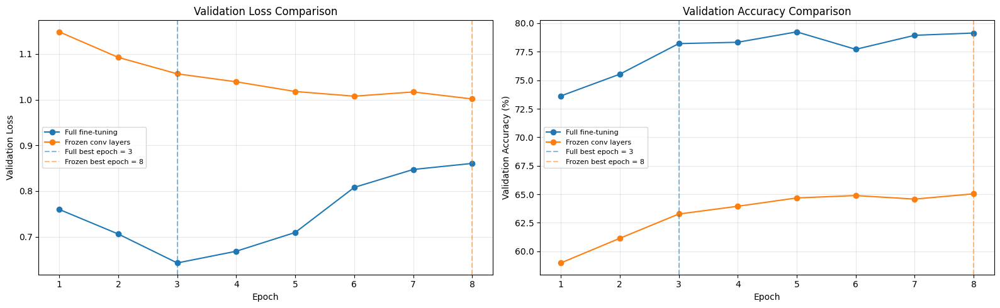

Full fine-tuning summary:
Best epoch: 3
Best validation loss: 0.6426
Best validation accuracy: 78.21%
Trainable parameters: 57,044,810

Frozen convolution layers summary:
Best epoch: 8
Best validation loss: 1.0015
Best validation accuracy: 65.04%
Trainable parameters: 54,575,114


In [ ]:
# Your graphs here and please provide comment in markdown in another cell
alexnet_compare_epochs = range(1, alexnet_full_num_epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(alexnet_compare_epochs, alexnet_full_history["valid_loss"], marker="o", label="Full fine-tuning")
axes[0].plot(alexnet_compare_epochs, alexnet_frozen_history["valid_loss"], marker="o", label="Frozen conv layers")
axes[0].axvline(alexnet_full_best_epoch, color="tab:blue", linestyle="--", alpha=0.5, label=f"Full best epoch = {alexnet_full_best_epoch}")
axes[0].axvline(alexnet_frozen_best_epoch, color="tab:orange", linestyle="--", alpha=0.5, label=f"Frozen best epoch = {alexnet_frozen_best_epoch}")
axes[0].set_title("Validation Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(alexnet_compare_epochs, alexnet_full_history["valid_acc"], marker="o", label="Full fine-tuning")
axes[1].plot(alexnet_compare_epochs, alexnet_frozen_history["valid_acc"], marker="o", label="Frozen conv layers")
axes[1].axvline(alexnet_full_best_epoch, color="tab:blue", linestyle="--", alpha=0.5, label=f"Full best epoch = {alexnet_full_best_epoch}")
axes[1].axvline(alexnet_frozen_best_epoch, color="tab:orange", linestyle="--", alpha=0.5, label=f"Frozen best epoch = {alexnet_frozen_best_epoch}")
axes[1].set_title("Validation Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Full fine-tuning summary:")
print(f"Best epoch: {alexnet_full_best_epoch}")
print(f"Best validation loss: {alexnet_full_best_valid_loss:.4f}")
print(f"Best validation accuracy: {alexnet_full_best_valid_acc:.2f}%")
print(f"Trainable parameters: {alexnet_full_trainable_params:,}")

print("\nFrozen convolution layers summary:")
print(f"Best epoch: {alexnet_frozen_best_epoch}")
print(f"Best validation loss: {alexnet_frozen_best_valid_loss:.4f}")
print(f"Best validation accuracy: {alexnet_frozen_best_valid_acc:.2f}%")
print(f"Trainable parameters: {alexnet_frozen_trainable_params:,}")

Full fine-tuning performs better than freezing the convolutional layers. The full fine-tuning model obtains its best validation loss of **0.6426** at **epoch 3**, with best validation accuracy **78.21%**. In comparison, the frozen-feature model obtains its best validation loss of **1.0015** at **epoch 8**, with best validation accuracy **65.04%**.

Although the frozen model trains fewer parameters in the feature extractor, it is less flexible because the convolutional layers cannot adapt to the CIFAR10 dataset. Full fine-tuning allows both the feature extractor and classifier to adjust to the target data, which explains the stronger validation performance.

However, full fine-tuning also has a higher risk of overfitting, as the validation loss starts to increase after the best epoch while training accuracy continues to rise. The frozen model is more stable but underfits compared with full fine-tuning.

### Part II: Multimodal data training [40 marks]


### Motivation

Through this part of assessment you will:

> 1. Use a Recurrent Neural Network (RNN) to predict the caption of an image from established word vocabularies
> 2. Understand and visualise text predictions for a given image.
> 3. Learn to use transformers for image embedding and transformer-based large language models for text embedding learning. (new)

#### Dataset
This assessment will use a subset of the [COCO "Common Objects in Context" dataset](https://cocodataset.org/) for image caption generation. COCO contains 330K images, of 80 object categories, and at least five textual reference captions per image. Our subset consists of nearly 5070 of these images, each of which has five or more different descriptions of the salient entities and activities, and we will refer to it as COCO_5070.

To download the data:

> 1. **Images and annotations**: download the zipped file provided in the link here as [``COMP5625M_data_assessment_2.zip``](https://leeds365-my.sharepoint.com/:u:/g/personal/scssali_leeds_ac_uk/EWWzE-_AIrlOkvOKxH4rjIgBF_eUx8KDJMPKM2eHwCE0dg?e=DdX62H).

``Info only:`` To understand more about the COCO dataset you can look at the [download page](https://cocodataset.org/#download). We have already provided you with the "2017 Train/Val annotations (241MB)" but our image subset consists of fewer images compared to orginial COCO dataset. So, no need to download anything from here!

> 2. **Image meta data**: as our set is a subset of full COCO dataset, we have created a CSV file containing relevant meta data for our particular subset of images. You can download it also from Drive, "coco_subset_meta.csv" at the same link as 1.

#### Submission

You can either submit the same file or make two separate .ipython notebook files zipped in the submission (please name as ``yourstudentusername_partI.ipynb`` and ``yourstudentusername_partII.ipynb``).

**Final note:**

> **Please include in this notebook everything that you would like to be marked, including figures. Under each section, put the relevant code containing your solution. You may re-use functions you defined previously, but any new code must be in the relevant section.** Feel free to add as many code cells as you need under each section.


The basic principle of our image-to-text model is as pictured in the diagram below, where an Encoder network encodes the input image as a feature vector by providing the outputs of the last fully-connected layer of a pre-trained CNN (we use [ResNet50](https://arxiv.org/abs/1512.03385)). This pretrained network has been trained on the complete ImageNet dataset and is thus able to recognise common objects.

You can alternatively use the COCO trained pretrained weights from [PyTorch](https://pytorch.org/vision/stable/models.html). One way to do this is use the "FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1" but use e.g., "resnet_model = model.backbone.body". Alternatively, you can use the checkpoint from your previous coursework where you fine-tuned to COCO dataset.

These features are then fed into a Decoder network along with the reference captions. As the image feature dimensions are large and sparse, the Decoder network includes a linear layer which downsizes them, followed by *a batch normalisation layer to speed up training*. Those resulting features, as well as the reference text captions, are then passed into a recurrent network (we will use an **RNNs** in this assessment).


### Sample RNN image captioning
The reference captions used to compute loss are represented as numerical vectors via an **embedding layer** whose weights are learned during training.

<!-- ![Encoder Decoder](comp5625M_figure.jpg) -->

<div>
<center><img src="comp5625M_figure_v3.jpg" width="1000"/></center>
</div>


### Instructions for creating vocabulary

A helper function file ``helperDL.py`` is provided that includes all the functions that will do the following for you. You can easily import these functions in the exercise, most are already done for you!  

> 1. Extracting image features (a pre-trained checkpoint is provided ``coco_features.pt`` for you to download and use it for training your RNN)
> 2. Text preparation of training and validation data is provided

In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms
import torchvision.models as models
from torch.utils.data import Dataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import matplotlib.pyplot as plt
from collections import Counter
import os
import numpy as np

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cpu


In [ ]:
# Load the feature map provided to you
features_map = torch.load('coco_features.pt', map_location=device)

#### 5 Train an RNN-based image captioning [20 marks]

Most of the background codes are provided to you. You only will require to write down the code based on your understanding to:

> 5.1 Design a RNN-based decoder. (8 marks)

> 5.2 Train your model with precomputed features. (6 Marks)

> 5.3 Train using new parameters. (6 Marks)




#### Text data preparation

In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/"))
print(os.listdir("/content/drive/MyDrive/COMP5625M_Summative Assessment_2026/"))

['Colab Notebooks', 'COMP5625M_Summative Assessment_2026', 'Flickr8k_Dataset', 'CLIP_ckpts']
['coco_subset_meta.csv', 'coco_features.pt', 'Comp5625M_logo.jpg', 'model_CLIP.py', 'model_S.pt', 'model_L.pt', 'comp5625M_figure_v3.jpg', 'helperDL.py', 'coco_captions.csv', 'notebook_zh_explained.md', 'COMP5625M_assessment2026_Summative_vFinal.ipynb', '.ipynb_checkpoints', 'tinyimagenet30', 'cifar10_data', 'coco', 'tinyimagenet30_final_model_checkpoint.pt', 'nplw0197.csv', '__pycache__', 'Images', 'coco_default_parameters.png', 'coco_default_parameters_decoder.ckpt', 'coco_new_parameters.png', 'coco_new_parameters_best_decoder.ckpt', 'clipcap-base-captioning-ft-hl-scenes']


In [ ]:
import pandas as pd
# captions.csv is provided to you
# coco/images/ folder is provided to you
base_path = "/content/drive/MyDrive/COMP5625M_Summative Assessment_2026/"
captions_path = base_path
image_path = base_path + "coco/images/"
df = pd.read_csv(captions_path+"coco_captions.csv")

#visualise
df.head(10)

,image_id,id,caption,image
0,9,661611,Closeup of bins of food that include broccoli ...,000000000009.jpg
1,9,661977,A meal is presented in brightly colored plasti...,000000000009.jpg
2,9,663627,there are containers filled with different kin...,000000000009.jpg
3,9,666765,"Colorful dishes holding meat, vegetables, frui...",000000000009.jpg
4,9,667602,A bunch of trays that have different food.,000000000009.jpg
5,25,127238,A giraffe mother with its baby in the forest.,000000000025.jpg
6,25,127076,A giraffe standing up nearby a tree,000000000025.jpg
7,25,133058,Two giraffes standing in a tree filled area.,000000000025.jpg
8,25,133676,A giraffe standing next to a forest filled wit...,000000000025.jpg
9,25,122312,A giraffe eating food from the top of the tree.,000000000025.jpg


In [ ]:
# Note: For RNN you will need to clean the text, for e.g., converting all uppercases to lowercases
# gen_clean_captions_df fuction will do this for you.

df["clean_caption"] = ""
from helperDL import gen_clean_captions_df
df_clean = gen_clean_captions_df(df)
df_clean.head(10)

,image_id,id,caption,image,clean_caption
0,9,661611,Closeup of bins of food that include broccoli ...,000000000009.jpg,closeup of bins of food that include broccoli ...
1,9,661977,A meal is presented in brightly colored plasti...,000000000009.jpg,a meal is presented in brightly colored plasti...
2,9,663627,there are containers filled with different kin...,000000000009.jpg,there are containers filled with different kin...
3,9,666765,"Colorful dishes holding meat, vegetables, frui...",000000000009.jpg,colorful dishes holding meat vegetables fruit ...
4,9,667602,A bunch of trays that have different food.,000000000009.jpg,a bunch of trays that have different food
5,25,127238,A giraffe mother with its baby in the forest.,000000000025.jpg,a giraffe mother with its baby in the forest
6,25,127076,A giraffe standing up nearby a tree,000000000025.jpg,a giraffe standing up nearby a tree
7,25,133058,Two giraffes standing in a tree filled area.,000000000025.jpg,two giraffes standing in a tree filled area
8,25,133676,A giraffe standing next to a forest filled wit...,000000000025.jpg,a giraffe standing next to a forest filled wit...
9,25,122312,A giraffe eating food from the top of the tree.,000000000025.jpg,a giraffe eating food from the top of the tree


In [ ]:
##### Spilt your training, validation and test dataset with indexes to each set
from helperDL import split_ids
train_id, valid_id, test_id = split_ids(df['id'].unique())
print("training:{}, validation:{}, test:{}".format(len(train_id), len(valid_id), len(test_id)))

training:17744, validation:2534, test:5071


In [ ]:
train_set = df.loc[df['id'].isin(train_id)]
valid_set = df.loc[df['id'].isin(valid_id)]
test_set = df.loc[df['id'].isin(test_id)]

In [ ]:
#### word 2 an integer ID - build vocabulary
class Vocabulary(object):
    """ Simple vocabulary wrapper which maps every unique word to an integer ID. """
    def __init__(self):
        # intially, set both the IDs and words to dictionaries with special tokens
        self.word2idx = {'<pad>': 0, '<unk>': 1, '<end>': 2}
        self.idx2word = {0: '<pad>', 1: '<unk>', 2: '<end>'}
        self.idx = 3

    def add_word(self, word):
        # if the word does not already exist in the dictionary, add it
        if not word in self.word2idx:
            self.word2idx[word] = self.idx
            self.idx2word[self.idx] = word
            # increment the ID for the next word
            self.idx += 1

    def __call__(self, word):
        # if we try to access a word not in the dictionary, return the id for <unk>
        if not word in self.word2idx:
            return self.word2idx['<unk>']
        return self.word2idx[word]

    def __len__(self):
        return len(self.word2idx)

In [ ]:
### build vocabulariy for each set - train, val and test
# you will be using to create dataloaders
from helperDL import build_vocab

# create a vocab instance
vocab = Vocabulary()
vocab_train = build_vocab(train_id, df_clean, vocab)
vocab_valid = build_vocab(valid_id, df_clean, vocab)
vocab_test = build_vocab(test_id, df_clean, vocab)

vocab = vocab_train # using only training samples as vocabulary as instructed above
print("Total vocabulary size: {}".format(len(vocab_train)))


Total vocabulary size: 2311


In [ ]:
# They can also join the train and valid captions but they will need to run vocabulary after concatenation
import numpy as np
vocab = build_vocab(np.concatenate((train_id, valid_id), axis=0), df_clean, vocab) #---> overrighting
len(vocab)

2495

Instantiate a ```DataLoader``` for your image feature and caption dataset. ``helperDL.py`` file includes all the required functions

We need to overwrite the default PyTorch collate_fn() because our
ground truth captions are sequential data of varying lengths. The default
collate_fn() does not support merging the captions with padding.

You can read more about it here:
https://pytorch.org/docs/stable/data.html#dataloader-collate-fn.


In [ ]:
from helperDL import EncoderCNN
model = EncoderCNN().to(device)
print(model)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 212MB/s]


EncoderCNN(
  (resnet): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (0): Conv2d(64

In [ ]:
''' Load the saved image feature maps and trained model ("provided to you") '''

# ---> your entry here (make sure that the path is correct - load the coco_features_{cpu/gpu}.pt)
features = torch.load("coco_features.pt")

# ---> load the model ckpt and udate the model state dict of the base model
# your entry here (make sure that the path is correct)
#checkpoint = torch.load("ckpt file here")
#model.load_state_dict(checkpoint['model_state_dict'])

In [ ]:
##### Preparing the train, val and test dataloaders
from helperDL import COCO_Features
from helperDL import caption_collate_fn

# Create a dataloader for train
dataset_train = COCO_Features(
    df=train_set,
    vocab=vocab,
    features=features_map,
)

train_loader = torch.utils.data.DataLoader(
    dataset_train,
    batch_size=32,
    shuffle=True,
    num_workers=0, # may need to set to 0
    collate_fn=caption_collate_fn, # explicitly overwrite the collate_fn
)

# Create a dataloader for valid
dataset_valid = COCO_Features(
    df=valid_set,
    vocab=vocab,
    features=features_map,
)

valid_loader = torch.utils.data.DataLoader(
    dataset_valid,
    batch_size=32,
    shuffle=True,
    num_workers=0, # may need to set to 0
    collate_fn=caption_collate_fn, # explicitly overwrite the collate_fn
)

In [ ]:
# Configuration file - You will be asked below to train your RNN using various configurations and compare.
# --> Please change these numbers as required.
# --> Please comment on changes that you do.

class cfg:
    EMBED_SIZE = 256
    HIDDEN_SIZE = 512
    NUM_LAYERS = 1
    LR = 0.001
    NUM_EPOCHS = 5
    LOG_STEP = 10
    MAX_SEQ_LEN = 37

#### 5.1 Design a RNN-based decoder (8 marks)

Read through the ```DecoderRNN``` model below. First, complete the decoder by adding an ```RNN``` layer to the decoder where indicated, using [the PyTorch API as reference](https://pytorch.org/docs/stable/nn.html#rnn).

Keep all the default parameters except for ```batch_first```, which you may set to True.

In particular, understand the meaning of ```pack_padded_sequence()``` as used in ```forward()```. Refer to the [PyTorch ```pack_padded_sequence()``` documentation](https://pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html).

In [ ]:
class DecoderRNN(nn.Module):
    def __init__(self, vocab_size, embed_size=cfg.EMBED_SIZE, hidden_size=cfg.HIDDEN_SIZE, num_layers=cfg.NUM_LAYERS, max_seq_length=cfg.MAX_SEQ_LEN):
        """Set the hyper-parameters and build the layers."""
        super(DecoderRNN, self).__init__()
        # we want a specific output size, which is the size of our embedding, so
        # we feed our extracted features from the last fc layer (dimensions 1 x 2048)
        # into a Linear layer to resize
        self.resize = nn.Linear(2048, embed_size)

        # batch normalisation helps to speed up training
        self.bn = nn.BatchNorm1d(embed_size, momentum=0.01)

        # Embedding layer
        self.embed = nn.Embedding(vocab_size, embed_size)

        # ---> RNN (use nn.RNN function passing arguments that you computed above, use batch_first=True as an argument)
        self.rnn = nn.RNN(embed_size, hidden_size, num_layers=num_layers, batch_first=True)

        self.linear = nn.Linear(hidden_size, vocab_size)
        self.max_seq_length = max_seq_length


    def forward(self, features, captions, lengths):
        """Decode image feature vectors and generates captions."""

        # a) compute the embedding of caption (Complete the code!)
        embeddings = self.embed(captions)
        # b) resize the image features (Complete the code!)
        im_features = self.resize(features)
        # c) apply batch norm on image the resized feature (Complete the code!)
        im_features = self.bn(im_features)
        # d) concatenate the image feature and the embeddings - use unsqueeze(1) to make the appropriate  size
        embeddings = torch.cat((im_features.unsqueeze(1), embeddings), 1)
        # e) use pack_padded_sequence
        packed = pack_padded_sequence(embeddings, lengths, batch_first=True)
        hiddens, _ = self.rnn(packed)
        outputs = self.linear(hiddens[0])
        return outputs


    def sample(self, features, states=None):
        """Generate captions for given image features using greedy search."""
        sampled_ids = []

        inputs = self.bn(self.resize(features)).unsqueeze(1)
        for i in range(self.max_seq_length):
            hiddens, states = self.rnn(inputs, states)  # hiddens: (batch_size, 1, hidden_size)
            outputs = self.linear(hiddens.squeeze(1))   # outputs:  (batch_size, vocab_size)
            _, predicted = outputs.max(1)               # predicted: (batch_size)
            sampled_ids.append(predicted)
            inputs = self.embed(predicted)              # inputs: (batch_size, embed_size)
            inputs = inputs.unsqueeze(1)                # inputs: (batch_size, 1, embed_size)
        sampled_ids = torch.stack(sampled_ids, 1)       # sampled_ids: (batch_size, max_seq_length)
        return sampled_ids

In [ ]:
# instantiate decoder
decoder = DecoderRNN(len(vocab), embed_size=cfg.EMBED_SIZE, hidden_size=cfg.HIDDEN_SIZE, num_layers=cfg.NUM_LAYERS).to(device)

##### 5.2 Train your model with precomputed features [6 marks]

Train the decoder by passing the features, reference captions, and targets to the decoder, then computing loss based on the outputs and the targets. Note that when passing the targets and model outputs to the loss function, the targets will also need to be formatted using ```pack_padded_sequence()```.

We recommend a batch size of around 64 (though feel free to adjust as necessary for your hardware).

**We strongly recommend saving a checkpoint of your trained model after training so you don't need to re-train multiple times.**

Display a graph of training and validation loss over epochs to justify your stopping point.

In [ ]:
# Define: loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(decoder.parameters(), lr=cfg.LR)

In [ ]:
def train():
    # train the models
    total_step = len(train_loader)
    total_step_v = len(valid_loader)
    stats = np.zeros((cfg.NUM_EPOCHS,2))
    print(stats.shape)
    total_loss = 0
    for epoch in range(cfg.NUM_EPOCHS):
        for i, (features_, captions_, lengths_) in enumerate(train_loader):

            # set mini-batch dataset
            features_ = features_.to(device)
            captions_ = captions_.to(device)
            targets = pack_padded_sequence(captions_, lengths_, batch_first=True)[0]
            decoder.zero_grad()

            # forward, backward and optimize
            outputs = decoder(features_, captions_, lengths_)
            loss = criterion(outputs, targets)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            # print stats
            if i % cfg.LOG_STEP == 0:
                print(f"Epoch [{epoch+1}/{cfg.NUM_EPOCHS}], Step [{i}/{total_step}], Loss: {loss.item():.4f}")

        stats[epoch,0] = round(total_loss/total_step,3)
        total_loss = 0
        decoder.eval()
        with torch.no_grad():
            for i, (features_, captions_, lengths_) in enumerate(valid_loader):

                # set mini-batch dataset
                features_ = features_.to(device)
                captions_ = captions_.to(device)
                targets = pack_padded_sequence(captions_, lengths_, batch_first=True)[0]

                # forward, backward and optimize
                outputs = decoder(features_, captions_, lengths_)

                loss = criterion(outputs, targets)

                total_loss += loss.item()

        stats[epoch,1] = round(total_loss/total_step_v,3)
        total_loss = 0
        # print stats
        print("="*30)
        print(f"Epoch [{epoch+1}/{cfg.NUM_EPOCHS}], Train_Loss: {stats[epoch,0]}, Valid_Loss: {stats[epoch,1]}")
        print("="*30)
        decoder.train()

    return stats

In [ ]:
def plot_stats(stats, figure_name="coco_train_vocab_only.png"):
    fig = plt.figure()
    plt.plot(stats[:,0], 'r', label = 'training', )
    plt.plot(stats[:,1], 'g', label = 'validation' )
    plt.legend()
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.title(f"COCO dataset- train vocab only #vocab={len(vocab)}")
    fig.savefig(figure_name)
    plt.show()

#### Train using default parameters

(5, 2)
Epoch [1/5], Step [0/555], Loss: 7.8635
Epoch [1/5], Step [10/555], Loss: 5.8415
Epoch [1/5], Step [20/555], Loss: 6.1297
Epoch [1/5], Step [30/555], Loss: 5.2961
Epoch [1/5], Step [40/555], Loss: 5.2559
Epoch [1/5], Step [50/555], Loss: 4.8990
Epoch [1/5], Step [60/555], Loss: 4.5179
Epoch [1/5], Step [70/555], Loss: 4.9092
Epoch [1/5], Step [80/555], Loss: 4.7808
Epoch [1/5], Step [90/555], Loss: 4.4856
Epoch [1/5], Step [100/555], Loss: 4.3395
Epoch [1/5], Step [110/555], Loss: 4.2603
Epoch [1/5], Step [120/555], Loss: 4.0562
Epoch [1/5], Step [130/555], Loss: 4.1426
Epoch [1/5], Step [140/555], Loss: 4.1093
Epoch [1/5], Step [150/555], Loss: 4.0732
Epoch [1/5], Step [160/555], Loss: 3.7409
Epoch [1/5], Step [170/555], Loss: 4.1392
Epoch [1/5], Step [180/555], Loss: 4.0416
Epoch [1/5], Step [190/555], Loss: 3.6916
Epoch [1/5], Step [200/555], Loss: 3.8029
Epoch [1/5], Step [210/555], Loss: 3.7691
Epoch [1/5], Step [220/555], Loss: 3.8278
Epoch [1/5], Step [230/555], Loss: 3.9

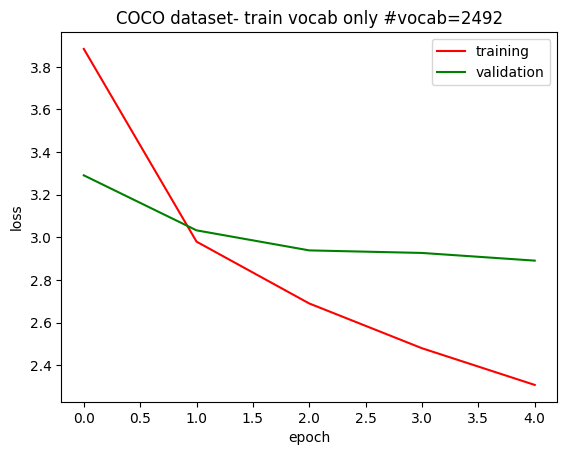

Decoder checkpoint saved to: coco_default_parameters_decoder.ckpt


In [ ]:
stats = train()
plot_stats(stats, "coco_default_parameters.png")

decoder_checkpoint_path = "coco_default_parameters_decoder.ckpt"
torch.save(
    {
        "decoder_state_dict": decoder.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "stats": stats,
        "embed_size": cfg.EMBED_SIZE,
        "hidden_size": cfg.HIDDEN_SIZE,
        "num_layers": cfg.NUM_LAYERS,
        "vocab_size": len(vocab),
    },
    decoder_checkpoint_path,
)
print(f"Decoder checkpoint saved to: {decoder_checkpoint_path}")

#### 5.3 Train using new parameters (6 Marks)

> In CFG class change --> NUM_LAYERS = 2 and  EMBED_SIZE = 512


Epoch [1/5], Step [0/555], Loss: 7.8205
Epoch [1/5], Step [10/555], Loss: 5.6692
Epoch [1/5], Step [20/555], Loss: 5.2034
Epoch [1/5], Step [30/555], Loss: 4.7429
Epoch [1/5], Step [40/555], Loss: 4.4461
Epoch [1/5], Step [50/555], Loss: 4.5786
Epoch [1/5], Step [60/555], Loss: 4.3234
Epoch [1/5], Step [70/555], Loss: 4.3079
Epoch [1/5], Step [80/555], Loss: 3.8832
Epoch [1/5], Step [90/555], Loss: 4.0629
Epoch [1/5], Step [100/555], Loss: 3.9230
Epoch [1/5], Step [110/555], Loss: 3.8822
Epoch [1/5], Step [120/555], Loss: 3.9936
Epoch [1/5], Step [130/555], Loss: 3.8945
Epoch [1/5], Step [140/555], Loss: 3.9650
Epoch [1/5], Step [150/555], Loss: 3.8336
Epoch [1/5], Step [160/555], Loss: 3.5440
Epoch [1/5], Step [170/555], Loss: 3.8310
Epoch [1/5], Step [180/555], Loss: 3.9389
Epoch [1/5], Step [190/555], Loss: 3.3371
Epoch [1/5], Step [200/555], Loss: 4.0421
Epoch [1/5], Step [210/555], Loss: 3.5734
Epoch [1/5], Step [220/555], Loss: 3.5062
Epoch [1/5], Step [230/555], Loss: 3.5521
Epo

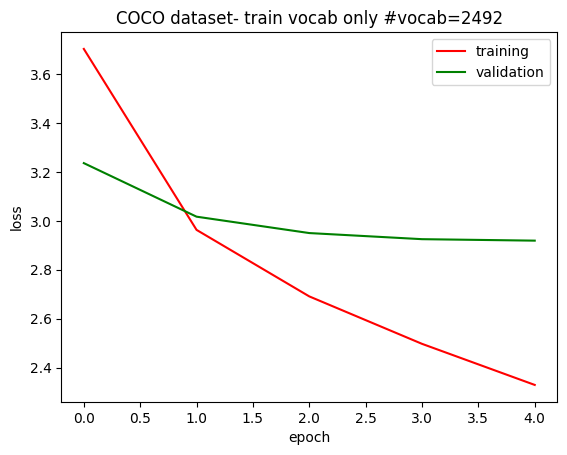

Best validation loss with new parameters: 2.919 at epoch 5


In [ ]:
#your code here!
import copy
cfg.NUM_LAYERS = 2
cfg.EMBED_SIZE = 512

decoder = DecoderRNN(
    len(vocab),
    embed_size=cfg.EMBED_SIZE,
    hidden_size=cfg.HIDDEN_SIZE,
    num_layers=cfg.NUM_LAYERS,
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(decoder.parameters(), lr=cfg.LR)

def train_new_config():
    total_step = len(train_loader)
    total_step_v = len(valid_loader)
    stats = np.zeros((cfg.NUM_EPOCHS, 2))
    total_loss = 0
    best_valid_loss = float("inf")
    best_epoch = 0
    best_decoder_state = copy.deepcopy(decoder.state_dict())

    for epoch in range(cfg.NUM_EPOCHS):
        for i, (features_, captions_, lengths_) in enumerate(train_loader):
            features_ = features_.to(device)
            captions_ = captions_.to(device)
            targets = pack_padded_sequence(captions_, lengths_, batch_first=True)[0]
            decoder.zero_grad()

            outputs = decoder(features_, captions_, lengths_)
            loss = criterion(outputs, targets)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            if i % cfg.LOG_STEP == 0:
                print(f"Epoch [{epoch+1}/{cfg.NUM_EPOCHS}], Step [{i}/{total_step}], Loss: {loss.item():.4f}")

        stats[epoch, 0] = round(total_loss / total_step, 3)
        total_loss = 0
        decoder.eval()

        with torch.no_grad():
            for i, (features_, captions_, lengths_) in enumerate(valid_loader):
                features_ = features_.to(device)
                captions_ = captions_.to(device)
                targets = pack_padded_sequence(captions_, lengths_, batch_first=True)[0]

                outputs = decoder(features_, captions_, lengths_)
                loss = criterion(outputs, targets)

                total_loss += loss.item()

        stats[epoch, 1] = round(total_loss / total_step_v, 3)

        if stats[epoch, 1] < best_valid_loss:
            best_valid_loss = stats[epoch, 1]
            best_epoch = epoch + 1
            best_decoder_state = copy.deepcopy(decoder.state_dict())

        total_loss = 0
        print("=" * 30)
        print(f"Epoch [{epoch+1}/{cfg.NUM_EPOCHS}], Train_Loss: {stats[epoch,0]}, Valid_Loss: {stats[epoch,1]}")
        print("=" * 30)
        decoder.train()

    return stats, best_decoder_state, best_valid_loss, best_epoch

new_config_stats, best_decoder_state, best_valid_loss, best_epoch = train_new_config()
decoder.load_state_dict(best_decoder_state)
plot_stats(new_config_stats, "coco_new_parameters.png")
print(f"Best validation loss with new parameters: {best_valid_loss:.3f} at epoch {best_epoch}")


In [ ]:
# save the best model after training
best_decoder_checkpoint_path = "coco_new_parameters_best_decoder.ckpt"
torch.save(
    {
        "decoder_state_dict": best_decoder_state,
        "optimizer_state_dict": optimizer.state_dict(),
        "stats": new_config_stats,
        "best_valid_loss": best_valid_loss,
        "best_epoch": best_epoch,
        "embed_size": cfg.EMBED_SIZE,
        "hidden_size": cfg.HIDDEN_SIZE,
        "num_layers": cfg.NUM_LAYERS,
        "vocab_size": len(vocab),
    },
    best_decoder_checkpoint_path,
)
print(f"Best decoder checkpoint saved to: {best_decoder_checkpoint_path}")


Best decoder checkpoint saved to: coco_new_parameters_best_decoder.ckpt


### 6 Test prediction and evaluation [8 marks]

#### 6.1 Generate predictions on test data (4 marks)

Display 4 sample test images containing different objects, along with your model’s generated captions and all the reference captions for each.

> Remember that everything **displayed** in the submitted notebook and .html file will be marked, so be sure to run all relevant cells.

In [ ]:
from helperDL import COCOImagesDataset

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406),   # using ImageNet norms
                         (0.229, 0.224, 0.225))])

dataset_test = COCOImagesDataset(
    df=test_set,
    transform=data_transform,
)
test_loader = torch.utils.data.DataLoader(
    dataset_test,
    batch_size=32,
    shuffle=False,
    num_workers=0)

In [ ]:
model.eval()
decoder.eval() # generate caption, eval mode to not influence batchnormncoder.eval()

DecoderRNN(
  (resize): Linear(in_features=2048, out_features=512, bias=True)
  (bn): BatchNorm1d(512, eps=1e-05, momentum=0.01, affine=True, track_running_stats=True)
  (embed): Embedding(2492, 512)
  (rnn): RNN(512, 512, num_layers=2, batch_first=True)
  (linear): Linear(in_features=512, out_features=2492, bias=True)
)

In [ ]:
# getting functions from helperDL.py
from helperDL import timshow
from helperDL import decode_caption

IMAGE: 000000000025.jpg
GENERATED: two giraffes in a pen with a <unk> in the background

REFERENCES:
- A giraffe mother with its baby in the forest.


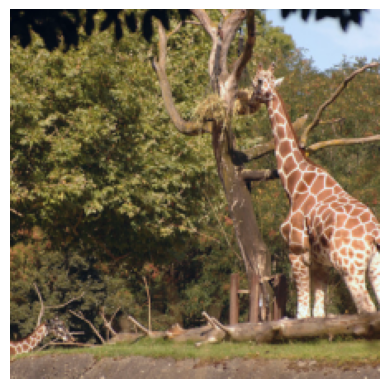

IMAGE: 000000000030.jpg
GENERATED: a red vase with flowers on a wooden surface

REFERENCES:
- A flower vase is sitting on a porch stand.


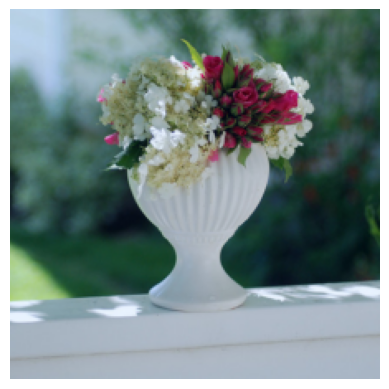

IMAGE: 000000000034.jpg
GENERATED: two zebra standing next to each other

REFERENCES:
- Zebra reaching its head down to ground where grass is. 
- A zebra grazing on lush green grass in a field.


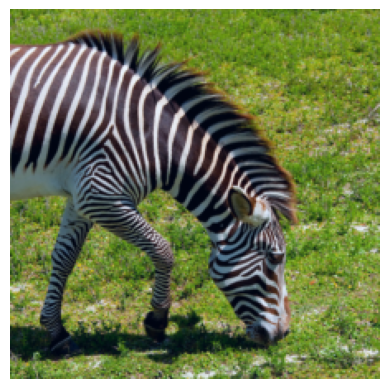

IMAGE: 000000000036.jpg
GENERATED: a woman in a sweatshirt with a red umbrella

REFERENCES:
- A woman in a floral swimsuit holds a pink umbrella.
- A woman with an umbrella near the sea
- A woman posing for the camera, holding a pink, open umbrella and wearing a bright, floral, ruched bathing suit, by a life guard stand with lake, green trees, and a blue sky with a few clouds behind.


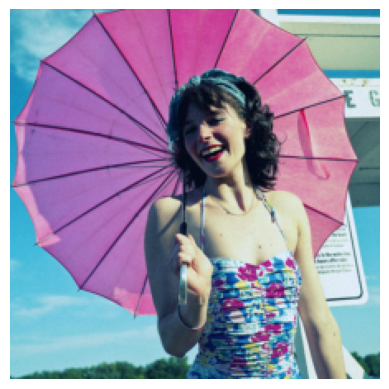

In [ ]:
IMAGES_TO_SHOW = 4
idx = 0
shown_filenames = set()
with torch.no_grad():
    for i, (image,filename) in enumerate(test_loader):

        image = image.to(device)
        features = model(image)
        sampled_ids = decoder.sample(features)

        for batch_idx in range(image.size(0)):
            current_filename = filename[batch_idx]
            if current_filename in shown_filenames:
                continue

            shown_filenames.add(current_filename)
            generated_caption = decode_caption(sampled_ids[batch_idx].cpu().numpy(), vocab)
            reference_captions = test_set.loc[test_set['image'] == current_filename, 'caption'].tolist()

            print(f"IMAGE: {current_filename}")
            print(f"GENERATED: {generated_caption}\n")
            print("REFERENCES:")
            for ref_caption in reference_captions:
                print(f"- {ref_caption}")

            print("===================================")

            timshow(image[batch_idx].cpu())
            idx +=1
            if idx == IMAGES_TO_SHOW:
                break

        if idx == IMAGES_TO_SHOW:
            break

#### 6.2 Caption evaluation using cosine similarity (4 marks)

The cosine similarity measures the cosine of the angle between two vectors in n-dimensional space. The smaller the angle, the greater the similarity.

To use the cosine similarity to measure the similarity between the generated caption and the reference captions:

* Find the embedding vector of each word in the caption
* Compute the average vector for each caption
* Compute the cosine similarity score between the average vector of the generated caption and average vector of each reference caption
* Compute the average of these scores

Calculate the cosine similarity using the model's predictions over the whole test set.

In [ ]:
# Section 6.2 diagnostic checks
import os
from pathlib import Path
import torch

print("=== Runtime / Device ===")
print(f"device variable: {device}")
print(f"torch.cuda.is_available(): {torch.cuda.is_available()}")

print("\n=== Model Types ===")
print(f"type(model): {type(model)}")
print(f"type(decoder): {type(decoder)}")

print("\n=== Parameter Devices ===")
try:
    print(f"next(model.parameters()).device: {next(model.parameters()).device}")
except Exception as e:
    print(f"model parameters unavailable: {e}")

try:
    print(f"next(decoder.parameters()).device: {next(decoder.parameters()).device}")
except Exception as e:
    print(f"decoder parameters unavailable: {e}")

print("\n=== Paths ===")
print(f"current working directory: {os.getcwd()}")

captions_path_value = globals().get("captions_path", None)
image_path_value = globals().get("image_path", None)

print(f"captions_path variable: {captions_path_value}")
print(f"image_path variable: {image_path_value}")

if captions_path_value is not None:
    print(f"captions_path absolute: {Path(captions_path_value).resolve()}")

if image_path_value is not None:
    print(f"image_path absolute: {Path(image_path_value).resolve()}")

default_coco_images = Path("./coco/images/").resolve()
print(f"default ./coco/images/ absolute path: {default_coco_images}")
print(f"default ./coco/images/ exists: {default_coco_images.exists()}")

alt_coco_images = Path("./COMP5625M_data_assessment_2/coco/images/").resolve()
print(f"alternative COCO images absolute path: {alt_coco_images}")
print(f"alternative COCO images exists: {alt_coco_images.exists()}")

print("\n=== Storage Risk Check ===")
path_candidates = [
    ("image_path", str(Path(image_path_value).resolve()) if image_path_value is not None else None),
    ("default_coco_images", str(default_coco_images)),
    ("alt_coco_images", str(alt_coco_images)),
]

for label, path_str in path_candidates:
    if path_str is None:
        continue
    lower_path = path_str.lower()
    on_drive = any(token in lower_path for token in ["/content/drive", "mydrive", "google drive", "onedrive"])
    print(f"{label}: {path_str}")
    if on_drive:
        print("  -> likely mounted/cloud drive path: higher I/O latency risk")
    else:
        print("  -> does not look like a mounted cloud-drive path")

print("\n=== Test Set Statistics ===")
print(f"len(test_set): {len(test_set)}")
print(f"test_set['image'].nunique(): {test_set['image'].nunique()}")
avg_caps = len(test_set) / test_set["image"].nunique()
print(f"average captions per unique image: {avg_caps:.2f}")

print("\n=== Test Loader ===")
print(f"len(test_loader): {len(test_loader)}")

print("\n=== Quick Bottleneck Ranking ===")
bottlenecks = []

try:
    model_type_name = type(model).__name__
    if model_type_name != "EncoderCNN":
        bottlenecks.append(
            f"1. model is currently {model_type_name}, not EncoderCNN -> Section 6.2 may be using the wrong visual encoder"
        )
except Exception:
    pass

try:
    if next(model.parameters()).device.type != "cuda":
        bottlenecks.append("2. model is not on CUDA -> image feature extraction may be much slower")
except Exception:
    bottlenecks.append("2. could not inspect model parameters -> model state may be inconsistent")

try:
    if next(decoder.parameters()).device.type != "cuda":
        bottlenecks.append("3. decoder is not on CUDA -> caption generation may be much slower")
except Exception:
    bottlenecks.append("3. could not inspect decoder parameters -> decoder state may be inconsistent")

if alt_coco_images.exists():
    lower_alt = str(alt_coco_images).lower()
    if any(token in lower_alt for token in ["/content/drive", "mydrive", "google drive", "onedrive"]):
        bottlenecks.append("4. COCO images appear to be on mounted/cloud storage -> reading many images can be slow")

if len(test_loader) > 50:
    bottlenecks.append("5. test_loader has many batches -> full-set inference may naturally take a while")

if not bottlenecks:
    bottlenecks.append("No obvious blocker found from static checks; next suspicion is slow full-dataset inference without progress prints")

for item in bottlenecks:
    print(item)


=== Runtime / Device ===
device variable: cuda
torch.cuda.is_available(): True

=== Model Types ===
type(model): <class 'helperDL.EncoderCNN'>
type(decoder): <class '__main__.DecoderRNN'>

=== Parameter Devices ===
next(model.parameters()).device: cuda:0
next(decoder.parameters()).device: cuda:0

=== Paths ===
current working directory: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026
captions_path variable: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/
image_path variable: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/coco/images/
captions_path absolute: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026
image_path absolute: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/coco/images
default ./coco/images/ absolute path: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/coco/images
default ./coco/images/ exists: True
alternative COCO images absolute path: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/COMP562

In [ ]:
# Section 6.2a - prepare local test-image cache
import os
import shutil
import time
from pathlib import Path

reference_caption_column = 'clean_caption' if 'clean_caption' in test_set.columns else 'caption'
unique_test_images = sorted(test_set['image'].unique())
reference_caption_dict = (
    test_set.groupby('image')[reference_caption_column]
    .apply(list)
    .to_dict()
)

source_image_dir = Path(image_path)
local_eval_dir = Path('/content/coco_eval_images')
local_eval_dir.mkdir(parents=True, exist_ok=True)

print(f"Unique evaluation images: {len(unique_test_images)}")
print(f"Source image directory: {source_image_dir}")
print(f"Local cache directory: {local_eval_dir}")

copy_start_time = time.time()
copied_count = 0
for index, filename in enumerate(unique_test_images, start=1):
    source_path = source_image_dir / filename
    destination_path = local_eval_dir / filename
    if not destination_path.exists():
        shutil.copy2(source_path, destination_path)
        copied_count += 1

    if index % 250 == 0 or index == len(unique_test_images):
        elapsed = time.time() - copy_start_time
        print(
            f"Copy progress: {index}/{len(unique_test_images)} | "
            f"new files copied: {copied_count} | elapsed: {elapsed:.1f}s"
        )

copy_elapsed = time.time() - copy_start_time
print(f"Local image cache ready: {local_eval_dir} | copied {copied_count} new files in {copy_elapsed:.1f}s")


Unique evaluation images: 3418
Source image directory: /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/coco/images
Local cache directory: /content/coco_eval_images
Copy progress: 250/3418 | new files copied: 191 | elapsed: 56.6s
Copy progress: 500/3418 | new files copied: 441 | elapsed: 133.0s
Copy progress: 750/3418 | new files copied: 691 | elapsed: 206.9s
Copy progress: 1000/3418 | new files copied: 941 | elapsed: 279.1s
Copy progress: 1250/3418 | new files copied: 1191 | elapsed: 350.5s
Copy progress: 1500/3418 | new files copied: 1441 | elapsed: 421.8s
Copy progress: 1750/3418 | new files copied: 1691 | elapsed: 490.8s
Copy progress: 2000/3418 | new files copied: 1941 | elapsed: 561.9s
Copy progress: 2250/3418 | new files copied: 2191 | elapsed: 634.2s
Copy progress: 2500/3418 | new files copied: 2441 | elapsed: 710.4s
Copy progress: 2750/3418 | new files copied: 2691 | elapsed: 782.5s
Copy progress: 3000/3418 | new files copied: 2941 | elapsed: 854.5s
Copy progress: 32

In [ ]:
# Section 6.2b - cosine similarity evaluation
import time
from PIL import UnidentifiedImageError
import torch.nn.functional as F

def caption_to_average_embedding(caption_text, vocab, embedding_layer, embedding_dim):
    words = str(caption_text).strip().lower().split()
    token_ids = [vocab(word) for word in words if word]

    if len(token_ids) == 0:
        return torch.zeros(embedding_dim, device=device)

    token_tensor = torch.tensor(token_ids, dtype=torch.long, device=device)
    token_embeddings = embedding_layer(token_tensor)
    return token_embeddings.mean(dim=0)

class LocalCOCOImagesDataset(torch.utils.data.Dataset):
    def __init__(self, filenames, image_dir, transform=None):
        self.filenames = list(filenames)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        filename = self.filenames[index]
        image = Image.open(self.image_dir / filename).convert('RGB')
        if self.transform is not None:
            image = self.transform(image)
        return image, filename

model.eval()
decoder.eval()

candidate_filenames = list(globals().get('verified_test_images', unique_test_images))
evaluation_filenames = []
skipped_unreadable = []
for filename in candidate_filenames:
    image_file = Path(local_eval_dir) / filename
    try:
        with Image.open(image_file) as img:
            img.verify()
        evaluation_filenames.append(filename)
    except (UnidentifiedImageError, OSError):
        skipped_unreadable.append(filename)

if skipped_unreadable:
    print(f"Skipping {len(skipped_unreadable)} unreadable images during evaluation filtering.")
    print(f"First few skipped files: {skipped_unreadable[:5]}")

local_test_loader = torch.utils.data.DataLoader(
    LocalCOCOImagesDataset(evaluation_filenames, local_eval_dir, transform=data_transform),
    batch_size=test_loader.batch_size,
    shuffle=False,
    num_workers=0,
)

embedding_dim = decoder.embed.embedding_dim
image_similarity_scores = []
evaluation_start_time = time.time()
num_batches = len(local_test_loader)

print(f"Starting cosine-similarity evaluation over {len(evaluation_filenames)} unique images and {num_batches} batches...")

with torch.no_grad():
    for batch_index, (images, filenames) in enumerate(local_test_loader, start=1):
        batch_start_time = time.time()
        images = images.to(device)
        features = model(images)
        sampled_ids = decoder.sample(features)

        for sample_idx, current_filename in enumerate(filenames):
            generated_caption = decode_caption(sampled_ids[sample_idx].cpu().numpy(), vocab)
            generated_embedding = caption_to_average_embedding(
                generated_caption,
                vocab,
                decoder.embed,
                embedding_dim,
            )

            reference_scores = []
            for reference_caption in reference_caption_dict[current_filename]:
                reference_embedding = caption_to_average_embedding(
                    reference_caption,
                    vocab,
                    decoder.embed,
                    embedding_dim,
                )
                cosine_score = F.cosine_similarity(
                    generated_embedding.unsqueeze(0),
                    reference_embedding.unsqueeze(0),
                    dim=1,
                ).item()
                reference_scores.append(cosine_score)

            if reference_scores:
                image_similarity_scores.append(sum(reference_scores) / len(reference_scores))

        batch_elapsed = time.time() - batch_start_time
        total_elapsed = time.time() - evaluation_start_time
        print(
            f"Batch {batch_index}/{num_batches} | "
            f"images processed: {len(image_similarity_scores)}/{len(evaluation_filenames)} | "
            f"batch time: {batch_elapsed:.2f}s | elapsed: {total_elapsed:.1f}s"
        )

average_cosine_similarity = sum(image_similarity_scores) / len(image_similarity_scores)
print(f"Average cosine similarity on the test set: {average_cosine_similarity:.4f}")
print(f"Number of evaluated test images: {len(image_similarity_scores)}")


Skipping 1 unreadable images during evaluation filtering.
First few skipped files: ['000000008314.jpg']
Starting cosine-similarity evaluation over 3417 unique images and 107 batches...
Batch 1/107 | images processed: 32/3417 | batch time: 0.22s | elapsed: 1.2s
Batch 2/107 | images processed: 64/3417 | batch time: 0.18s | elapsed: 2.1s
Batch 3/107 | images processed: 96/3417 | batch time: 0.19s | elapsed: 3.0s
Batch 4/107 | images processed: 128/3417 | batch time: 0.33s | elapsed: 4.5s
Batch 5/107 | images processed: 160/3417 | batch time: 0.22s | elapsed: 6.4s
Batch 6/107 | images processed: 192/3417 | batch time: 0.26s | elapsed: 8.1s
Batch 7/107 | images processed: 224/3417 | batch time: 0.13s | elapsed: 9.0s
Batch 8/107 | images processed: 256/3417 | batch time: 0.20s | elapsed: 9.9s
Batch 9/107 | images processed: 288/3417 | batch time: 0.14s | elapsed: 10.7s
Batch 10/107 | images processed: 320/3417 | batch time: 0.15s | elapsed: 11.6s
Batch 11/107 | images processed: 352/3417 | b

## 7 Use language models for image captioning [12 marks]

Description: A large language model (LLM) is a type of artificial intelligence (AI) model that uses deep learning to perform natural language processing (NLP) tasks.

One way to train on multimodal (image and text data) is CLIP (Contrastive Language-Image Pre-Training). CLIP is a neural network trained on a variety of (image, text) pairs and can take CNNs or transformers for encoding images and widely accepted LLMs for text embedding. Paper here: https://arxiv.org/pdf/2103.00020

CLIP is trained on flickr 30K dataset. First we will try on flickr 8k data then on COCO.

You can download flickr 8k [here](https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_Dataset.zip)

> Most codes are provided for you.
> Small model and large pre-trained models are given to you and also we have provided the configS and configL that are required to run these models.

> **Your task is to:**

    - a. Understand how the smaller model perform on the flickr 8k and COCO dataset (2 images each) [4 marks]

    - b. Understand how the larger model perform on the flickr 8k and COCO dataset (2 images each) [4 marks]
    
    - c. Finally, understand how the CLIP model trained on a larger curated COCO dataset generalises to the COCO dataset (use same 2 images from above) [4 marks]


You can find the link to download small and large pretrained CLIP models also here: [CLIP_S_L_Models](https://leeds365-my.sharepoint.com/:u:/g/personal/scssali_leeds_ac_uk/IQC-n5cRoq8ORKz1AwD8xwf8AQScRIg2jFfnzL5SAceNXoo?e=jeBWsZ)

In [ ]:
import os

#configuration for the smaller model (slightly over 1 GB model weight file)

class configS:
    """
    Project's main config.
    """

    clip_model: str = "openai/clip-vit-base-patch32"
    text_model: str = "gpt2"
    seed: int = 100
    num_workers: int = 2
    train_size: int = 0.84
    val_size: int = 0.13
    epochs: int = 150
    lr: int = 3e-3
    k: float = 0.33
    batch_size_exp: int = 6
    ep_len: int = 4
    num_layers: int = 6
    n_heads: int = 16
    forward_expansion: int = 4
    max_len: int = 40
    dropout: float = 0.1
    weights_dir: str = os.path.join("weights", "small")

In [ ]:
#configuration for the larger model (nearly 3 GB model weight file)
class configL:
    """
    Project's main config - large.
    """

    clip_model: str = "openai/clip-vit-large-patch14"
    text_model: str = "gpt2-medium"
    seed: int = 100
    num_workers: int = 2
    train_size: int = 0.84
    val_size: int = 0.13
    epochs: int = 120
    lr: int = 5e-3
    k: float = 0.3
    batch_size_exp: int = 5
    ep_len: int = 4
    num_layers: int = 5
    n_heads: int = 16
    forward_expansion: int = 4
    max_len: int = 40
    dropout: float = 0.08
    weights_dir: str = os.path.join("weights", "large")

In [ ]:
from model_CLIP import Net # function is given to you

model = Net(
    clip_model=configS.clip_model,
    text_model=configS.text_model,
    ep_len=configS.ep_len,
    num_layers=configS.num_layers,
    n_heads=configS.n_heads,
    forward_expansion=configS.forward_expansion,
    dropout=configS.dropout,
    max_len=configS.max_len,
    device=device,
)

#use small model
checkpoint = torch.load('model_S.pt', map_location=device)
model.load_state_dict(checkpoint, strict=False)
# model.load_state_dict(checkpoint, strict=False)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

_IncompatibleKeys(missing_keys=[], unexpected_keys=['ie.model.embeddings.position_ids', 'td.model.transformer.h.0.attn.bias', 'td.model.transformer.h.0.attn.masked_bias', 'td.model.transformer.h.1.attn.bias', 'td.model.transformer.h.1.attn.masked_bias', 'td.model.transformer.h.2.attn.bias', 'td.model.transformer.h.2.attn.masked_bias', 'td.model.transformer.h.3.attn.bias', 'td.model.transformer.h.3.attn.masked_bias', 'td.model.transformer.h.4.attn.bias', 'td.model.transformer.h.4.attn.masked_bias', 'td.model.transformer.h.5.attn.bias', 'td.model.transformer.h.5.attn.masked_bias', 'td.model.transformer.h.6.attn.bias', 'td.model.transformer.h.6.attn.masked_bias', 'td.model.transformer.h.7.attn.bias', 'td.model.transformer.h.7.attn.masked_bias', 'td.model.transformer.h.8.attn.bias', 'td.model.transformer.h.8.attn.masked_bias', 'td.model.transformer.h.9.attn.bias', 'td.model.transformer.h.9.attn.masked_bias', 'td.model.transformer.h.10.attn.bias', 'td.model.transformer.h.10.attn.masked_bias

> Try on COCO dataset with the small model only - Comment on your observation.

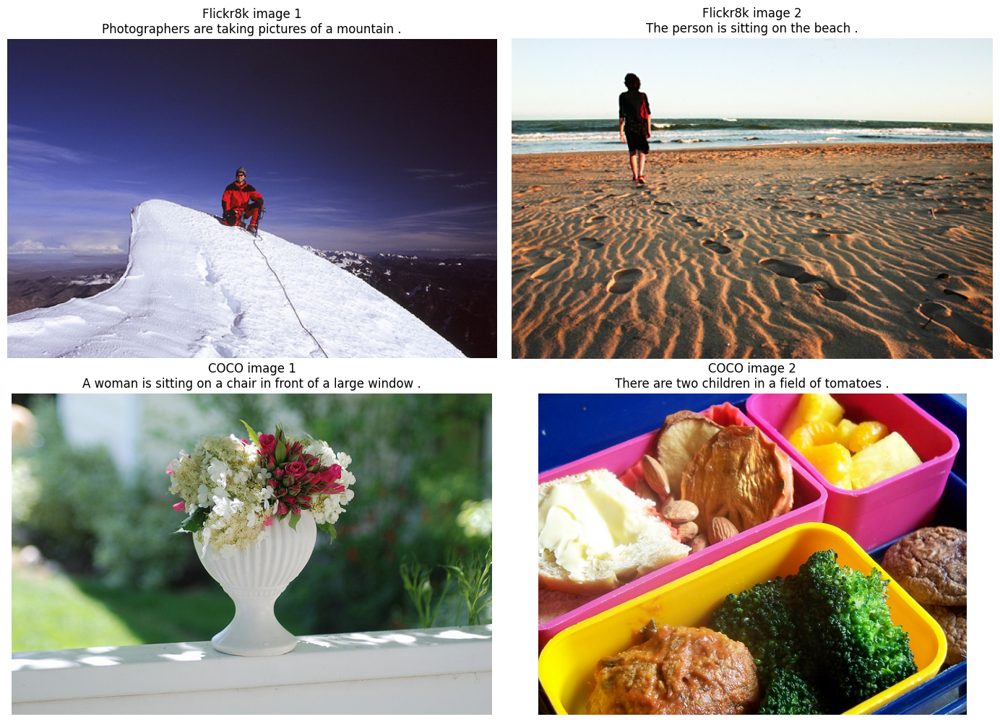

In [ ]:
model.eval()
from PIL import Image

def generate_caption_small_model(model, img, temperature=1.0):
    if temperature <= 0.0:
        temperature = 1.0

    with torch.no_grad():
        img_embedded = model.ie(img)
        img_mapped = model.mp(img_embedded)

        sos_emb = model.td.model.transformer.wte(
            torch.tensor(model.td.tokenizer.bos_token_id).to(device)
        ).unsqueeze(0)

        start_emb = torch.cat([sos_emb, img_mapped], dim=0)

        tokens = []
        for _ in range(model.max_len):
            if len(tokens):
                tok_emb = model.td.model.transformer.wte(
                    torch.tensor(tokens).to(device)
                )
                emb = torch.cat([start_emb, tok_emb], dim=0)
            else:
                emb = start_emb

            pos_emb = model.td.model.transformer.wpe(
                torch.arange(emb.shape[0]).to(device)
            )
            emb = emb + pos_emb

            # GPT2 expects [batch, seq, hidden]
            pred = model.td(emb.unsqueeze(0))
            pred = torch.softmax(pred / temperature, dim=-1)

            _, pred = torch.max(pred, dim=2)
            last_token = pred[0, -1].item()
            tokens.append(last_token)

            if last_token == model.td.tokenizer.eos_token_id:
                break

        decoded = model.td.tokenizer.decode(tokens[:-1])
        decoded = decoded.strip()
        if len(decoded) > 0:
            decoded = decoded[0].upper() + decoded[1:]

        return decoded, tokens


# Output on two images of your choice from 'flickr 8k'
small_model_flickr_images = [
    'Images/55473406_1d2271c1f2.jpg',
    'Images/260828892_7925d27865.jpg',
]

# Output on two images of your choice from 'COCO' dataset
small_model_coco_images = [
    os.path.join(image_path, '000000000030.jpg'),
    os.path.join(image_path, '000000000009.jpg'),
]

small_model_image_paths = list(small_model_flickr_images) + list(small_model_coco_images)
small_model_titles = ['Flickr8k image 1', 'Flickr8k image 2', 'COCO image 1', 'COCO image 2']

temperature = 1.0
plt.figure(figsize=(14, 10))
with torch.no_grad():
    for idx, (img_path, image_title) in enumerate(zip(small_model_image_paths, small_model_titles), start=1):
        img = Image.open(img_path).convert('RGB')
        caption, _ = generate_caption_small_model(model, img, temperature)

        plt.subplot(2, 2, idx)
        plt.imshow(img)
        plt.title(f"{image_title}\n{caption}")
        plt.axis("off")

plt.tight_layout()
plt.show()


The small captioning model produces mixed results on the COCO images. It can identify some broad scene-level concepts, such as a person on a beach, but the captions are often inaccurate or overly generic. For example, the mountain image is described as “photographers are taking pictures of a mountain”, although the image mainly shows a single climber or mountaineer on snow. The flower image is incorrectly described as a woman sitting by a window, and the food image is incorrectly described as two children in a field of tomatoes. This suggests that the small model has limited visual grounding and struggles with object-level details, especially when the image content differs from common patterns seen during training.

<--- Your comment here --->

> Repeat the above with the larger model "model_L" - use large model configuration. Comment on your observations.

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.52G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2-medium
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...23}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

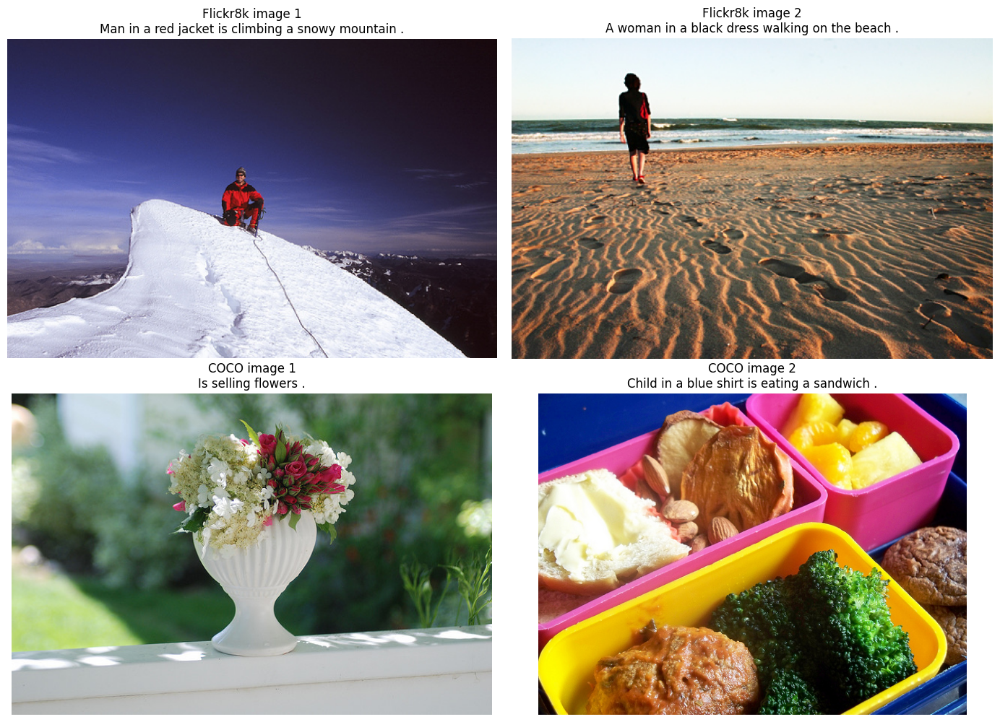

In [ ]:
###Your code here!
large_model = Net(
    clip_model=configL.clip_model,
    text_model=configL.text_model,
    ep_len=configL.ep_len,
    num_layers=configL.num_layers,
    n_heads=configL.n_heads,
    forward_expansion=configL.forward_expansion,
    dropout=configL.dropout,
    max_len=configL.max_len,
    device=device,
)

checkpoint = torch.load('model_L.pt', map_location=device)
large_model.load_state_dict(checkpoint, strict=False)
large_model = large_model.to(device)
large_model.eval()

def generate_caption_large_model(model, img, temperature=1.0):
    if temperature <= 0.0:
        temperature = 1.0

    with torch.no_grad():
        img_embedded = model.ie(img)
        img_mapped = model.mp(img_embedded)

        sos_emb = model.td.model.transformer.wte(
            torch.tensor(model.td.tokenizer.bos_token_id).to(device)
        ).unsqueeze(0)

        start_emb = torch.cat([sos_emb, img_mapped], dim=0)

        tokens = []
        for _ in range(model.max_len):
            if len(tokens):
                tok_emb = model.td.model.transformer.wte(
                    torch.tensor(tokens).to(device)
                )
                emb = torch.cat([start_emb, tok_emb], dim=0)
            else:
                emb = start_emb

            pos_emb = model.td.model.transformer.wpe(
                torch.arange(emb.shape[0]).to(device)
            )
            emb = emb + pos_emb

            # GPT2 expects [batch, seq, hidden]
            pred = model.td(emb.unsqueeze(0))
            pred = torch.softmax(pred / temperature, dim=-1)

            _, pred = torch.max(pred, dim=2)
            last_token = pred[0, -1].item()
            tokens.append(last_token)

            if last_token == model.td.tokenizer.eos_token_id:
                break

        decoded = model.td.tokenizer.decode(tokens[:-1])
        decoded = decoded.strip()
        if len(decoded) > 0:
            decoded = decoded[0].upper() + decoded[1:]

        return decoded, tokens


flickr_image_paths = globals().get(
    'small_model_flickr_images',
    ['Images/55473406_1d2271c1f2.jpg', 'Images/260828892_7925d27865.jpg']
)
coco_image_paths = globals().get(
    'small_model_coco_images',
    [os.path.join(image_path, '000000000030.jpg'), os.path.join(image_path, '000000000009.jpg')]
)

large_model_image_paths = list(flickr_image_paths) + list(coco_image_paths)
large_model_titles = ['Flickr8k image 1', 'Flickr8k image 2', 'COCO image 1', 'COCO image 2']

temperature = 1.0
plt.figure(figsize=(14, 10))
with torch.no_grad():
    for idx, (img_path, image_title) in enumerate(zip(large_model_image_paths, large_model_titles), start=1):
        img = Image.open(img_path).convert('RGB')
        caption, _ = generate_caption_large_model(large_model, img, temperature)

        plt.subplot(2, 2, idx)
        plt.imshow(img)
        plt.title(f"{image_title}\n{caption}")
        plt.axis('off')

plt.tight_layout()
plt.show()


The larger model does not consistently improve the caption quality on these COCO examples. It still makes several major semantic errors. For example, the flower image is captioned as “is selling flowers”, which partially recognises the presence of flowers but incorrectly introduces an action and a person that are not visible. The food image is described as “Child in a blue shirt is eating a sandwich”, although the image only shows lunchbox food and no child. The beach image is closer to the visual content because it identifies a person at the beach, but the caption is still not very detailed. Overall, increasing the model size appears to improve some object recognition slightly, but the generated captions remain unreliable and often hallucinate people or actions not present in the image.

> Try on COCO dataset with the large model only - Comment on your observation. What would you have to do to improve network performance?

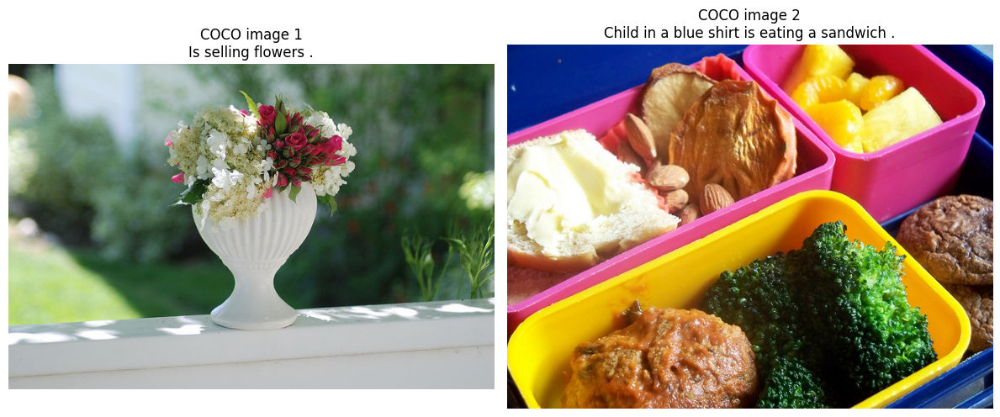

In [ ]:
###Your code here!
large_model.eval()

def generate_caption_large_model(model, img, temperature=1.0):
    if temperature <= 0.0:
        temperature = 1.0

    with torch.no_grad():
        img_embedded = model.ie(img)
        img_mapped = model.mp(img_embedded)

        sos_emb = model.td.model.transformer.wte(
            torch.tensor(model.td.tokenizer.bos_token_id).to(device)
        ).unsqueeze(0)

        start_emb = torch.cat([sos_emb, img_mapped], dim=0)

        tokens = []
        for _ in range(model.max_len):
            if len(tokens):
                tok_emb = model.td.model.transformer.wte(
                    torch.tensor(tokens).to(device)
                )
                emb = torch.cat([start_emb, tok_emb], dim=0)
            else:
                emb = start_emb

            pos_emb = model.td.model.transformer.wpe(
                torch.arange(emb.shape[0]).to(device)
            )
            emb = emb + pos_emb

            pred = model.td(emb.unsqueeze(0))
            pred = torch.softmax(pred / temperature, dim=-1)

            _, pred = torch.max(pred, dim=2)
            last_token = pred[0, -1].item()
            tokens.append(last_token)

            if last_token == model.td.tokenizer.eos_token_id:
                break

        decoded = model.td.tokenizer.decode(tokens[:-1])
        decoded = decoded.strip()
        if len(decoded) > 0:
            decoded = decoded[0].upper() + decoded[1:]

        return decoded, tokens


coco_image_paths = globals().get(
    'small_model_coco_images',
    [os.path.join(image_path, '000000000030.jpg'), os.path.join(image_path, '000000000009.jpg')]
)

temperature = 1.0
plt.figure(figsize=(12, 5))
with torch.no_grad():
    for idx, img_path in enumerate(coco_image_paths[:2], start=1):
        img = Image.open(img_path).convert('RGB')
        caption, _ = generate_caption_large_model(large_model, img, temperature)

        plt.subplot(1, 2, idx)
        plt.imshow(img)
        plt.title(f"COCO image {idx}\n{caption}")
        plt.axis('off')

plt.tight_layout()
plt.show()


The COCO-only outputs suggest that the model has learned frequent image-caption patterns from the COCO training data, but the grounding is still weak. In the flower example, the generated caption is partly related to the image because it mentions flowers, but it hallucinates the action of selling. In the lunchbox example, the model generates a plausible COCO-style sentence about a child eating a sandwich, although no child is present. This indicates that the model sometimes relies on language priors rather than the actual image content.

##### Now try on the CLIP fine-tuned on High-Level dataset.

The High-Level (HL) dataset aligns object-centric descriptions from COCO with high-level descriptions crowdsourced along 3 axes: scene, action, rationale.

The HL dataset contains 14997 images from COCO and a total of 134973 crowdsourced captions (3 captions for each axis) aligned with ~749984 object-centric captions from COCO.

https://huggingface.co/datasets/michelecafagna26/hl

In [ ]:
#run these to install CLIPClap - fine tuned on COCO

!pip install git+https://github.com/michelecafagna26/CLIPCap.git

!git lfs install
!git clone https://huggingface.co/michelecafagna26/clipcap-base-captioning-ft-hl-scenes

  Cloning https://github.com/michelecafagna26/CLIPCap.git to /tmp/pip-req-build-88c1wyuq
  Running command git clone --filter=blob:none --quiet https://github.com/michelecafagna26/CLIPCap.git /tmp/pip-req-build-88c1wyuq
  Resolved https://github.com/michelecafagna26/CLIPCap.git to commit 545c5574fee8e3a56dec3e5c3f86388269a06f1d
  Preparing metadata (setup.py) ... done
  Cloning https://github.com/openai/CLIP (to revision main) to /tmp/pip-install-rle1bq5s/clip_bdd47e4f91134492a1e7884a7149d88b
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP /tmp/pip-install-rle1bq5s/clip_bdd47e4f91134492a1e7884a7149d88b
  Resolved https://github.com/openai/CLIP to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done
Git LFS initialized.
fatal: destination path 'clipcap-base-captioning-ft-hl-scenes' already exists and is not an empty directory.


In [ ]:
from clipcap import ClipCaptionModel
from transformers import GPT2Tokenizer, GPT2LMHeadModel
import torch
import clip
import requests
from PIL import Image

model_path = "clipcap-base-captioning-ft-hl-scenes/pytorch_model.pt" # change accordingly

# load clip
device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model, preprocess = clip.load("ViT-B/32", device=device, jit=False)
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
prefix_length = 10

# load ClipCap
model = ClipCaptionModel(prefix_length, tokenizer=tokenizer)
model.from_pretrained(model_path)
model = model.eval()
model = model.to(device)


100%|███████████████████████████████████████| 338M/338M [00:03<00:00, 96.3MiB/s]


Downloading:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

Downloading: 0.00B [00:00, ?B/s]

Downloading: 0.00B [00:00, ?B/s]

Downloading: 0.00B [00:00, ?B/s]

Downloading:   0%|          | 0.00/665 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/523M [00:00<?, ?B/s]

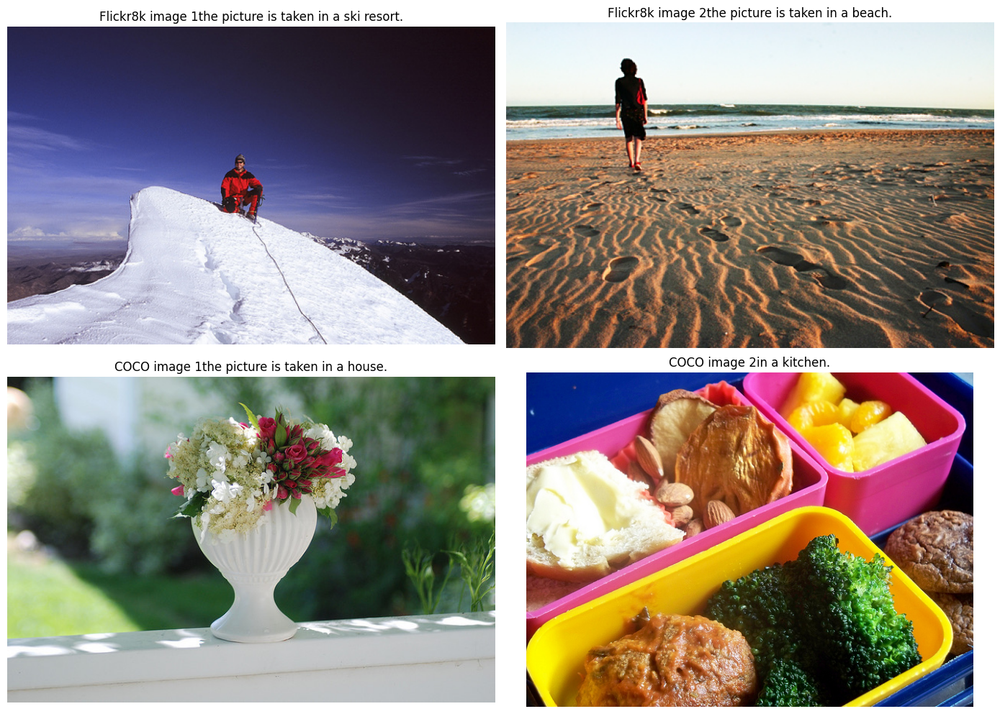

In [ ]:

# load the image
# raw_image = Image.open('Images/260828892_7925d27865.jpg').convert('RGB')
# raw_image = Image.open(image_path + './000000000030.jpg').convert('RGB')

# Your code here --->
flickr_image_paths = globals().get(
    'small_model_flickr_images',
    ['Images/55473406_1d2271c1f2.jpg', 'Images/260828892_7925d27865.jpg']
)
coco_image_paths = globals().get(
    'small_model_coco_images',
    [os.path.join(image_path, '000000000030.jpg'), os.path.join(image_path, '000000000009.jpg')]
)

clipcap_image_paths = list(flickr_image_paths) + list(coco_image_paths)
clipcap_titles = ['Flickr8k image 1', 'Flickr8k image 2', 'COCO image 1', 'COCO image 2']

plt.figure(figsize=(14, 10))
for idx, (img_path, image_title) in enumerate(zip(clipcap_image_paths, clipcap_titles), start=1):
    raw_image = Image.open(img_path).convert('RGB')

    # extract the prefix
    img = preprocess(raw_image).unsqueeze(0).to(device)
    with torch.no_grad():
        prefix = clip_model.encode_image(img).to(
            device, dtype=torch.float32
        )
        prefix_embed = model.clip_project(prefix).reshape(1, prefix_length, -1)

    # generate the caption
    caption = model.generate_beam(embed=prefix_embed)[0]

    plt.subplot(2, 2, idx)
    plt.imshow(raw_image)
    plt.title(f"{image_title}{caption}")
    plt.axis("off")

plt.tight_layout()
plt.show()

The fine-tuned CLIPCap model produces more scene-level captions than the previous captioning models. It correctly identifies the broad location for some images, such as describing the beach image as taken on a beach and the food image as taken in a kitchen. However, the captions are still quite generic and sometimes miss the main object-level content. For example, the flower image is described as being taken in a house, even though the visible content is mainly a vase of flowers outdoors or near a window. The mountain image is described as a ski resort, which is related to snow and mountains but does not mention the climber. Overall, the CLIP-based model appears better at recognising the general scene, but it still lacks detailed and precise captioning of the key objects and actions.

<Your answer here>

##### Thank you for completing the practical assessment - if you have any question, please ask on teams channel or attend lab sessions on Mondays, Wednesdays and Thursdays.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

import json
from pathlib import Path
from datetime import datetime

notebook_path = Path("/content/drive/MyDrive/COMP5625M_Summative Assessment_2026/COMP5625M_assessment2026_Summative_vFinal.ipynb")

if not notebook_path.exists():
    raise FileNotFoundError(f"Notebook not found: {notebook_path}")

print("Using notebook:")
print(notebook_path)
print("Last modified:", datetime.fromtimestamp(notebook_path.stat().st_mtime))

patched_path = notebook_path.with_name(notebook_path.stem + "_nbconvert_patched.ipynb")

nb = json.loads(notebook_path.read_text(encoding="utf-8"))

mime = "application/vnd.jupyter.widget-state+json"
widgets_container = nb.setdefault("metadata", {}).setdefault("widgets", {})

widget_data = widgets_container.get(mime)

if isinstance(widget_data, dict) and "state" not in widget_data:
    widgets_container[mime] = {
        "state": widget_data,
        "version_major": 2,
        "version_minor": 0,
    }
elif widget_data is None:
    widgets_container[mime] = {
        "state": {},
        "version_major": 2,
        "version_minor": 0,
    }

patched_path.write_text(json.dumps(nb, ensure_ascii=False), encoding="utf-8")

print("Patched notebook saved to:")
print(patched_path)

!jupyter nbconvert --to html --embed-images "$patched_path"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using notebook:
/content/drive/MyDrive/COMP5625M_Summative Assessment_2026/COMP5625M_assessment2026_Summative_vFinal.ipynb
Last modified: 2026-04-24 20:03:06
Patched notebook saved to:
/content/drive/MyDrive/COMP5625M_Summative Assessment_2026/COMP5625M_assessment2026_Summative_vFinal_nbconvert_patched.ipynb
[NbConvertApp] Converting notebook /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/COMP5625M_assessment2026_Summative_vFinal_nbconvert_patched.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 20 image(s).
[NbConvertApp] Writing 11003354 bytes to /content/drive/MyDrive/COMP5625M_Summative Assessment_2026/COMP5625M_assessment2026_Summative_vFinal_nbconvert_patched.html
